# Exploratory Visualization with ggplot2

This notebook follows the analysis sequence. Each step explains the operation being performed; data and computational formulas are retained. Run all cells locally to refresh the saved figures.


## Dataset inspection and initial relationships


In [1]:
# Inspect several observations in the bundled diamonds example.
library(ggplot2)
head(diamonds)

,carat,cut,color,clarity,depth,table,price,x,y,z
,<dbl>,<ord>,<ord>,<ord>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
1,0.23,Ideal,E,SI2,61.5,55,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.8,61,326,3.89,3.84,2.31
3,0.23,Good,E,VS1,56.9,65,327,4.05,4.07,2.31
4,0.29,Premium,I,VS2,62.4,58,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.3,58,335,4.34,4.35,2.75
6,0.24,Very Good,J,VVS2,62.8,57,336,3.94,3.96,2.48


In [2]:
# Review marginal statistics and category ranges for diamond measurements.
summary(diamonds)

     carat               cut        color        clarity          depth      
 Min.   :0.2000   Fair     : 1610   D: 6775   SI1    :13065   Min.   :43.00  
 1st Qu.:0.4000   Good     : 4906   E: 9797   VS2    :12258   1st Qu.:61.00  
 Median :0.7000   Very Good:12082   F: 9542   SI2    : 9194   Median :61.80  
 Mean   :0.7979   Premium  :13791   G:11292   VS1    : 8171   Mean   :61.75  
 3rd Qu.:1.0400   Ideal    :21551   H: 8304   VVS2   : 5066   3rd Qu.:62.50  
 Max.   :5.0100                     I: 5422   VVS1   : 3655   Max.   :79.00  
                                    J: 2808   (Other): 2531                  
     table           price             x                y         
 Min.   :43.00   Min.   :  326   Min.   : 0.000   Min.   : 0.000  
 1st Qu.:56.00   1st Qu.:  950   1st Qu.: 4.710   1st Qu.: 4.720  
 Median :57.00   Median : 2401   Median : 5.700   Median : 5.710  
 Mean   :57.46   Mean   : 3933   Mean   : 5.731   Mean   : 5.735  
 3rd Qu.:59.00   3rd Qu.: 5324   3rd Qu.:

In [3]:
# Preview the built-in iris dataset.
head(iris)

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


In [4]:
# Compare the summary statistics of the iris measurements.
summary(iris)

  Sepal.Length    Sepal.Width     Petal.Length    Petal.Width   
 Min.   :4.300   Min.   :2.000   Min.   :1.000   Min.   :0.100  
 1st Qu.:5.100   1st Qu.:2.800   1st Qu.:1.600   1st Qu.:0.300  
 Median :5.800   Median :3.000   Median :4.350   Median :1.300  
 Mean   :5.843   Mean   :3.057   Mean   :3.758   Mean   :1.199  
 3rd Qu.:6.400   3rd Qu.:3.300   3rd Qu.:5.100   3rd Qu.:1.800  
 Max.   :7.900   Max.   :4.400   Max.   :6.900   Max.   :2.500  
       Species  
 setosa    :50  
 versicolor:50  
 virginica :50  
                
                
                

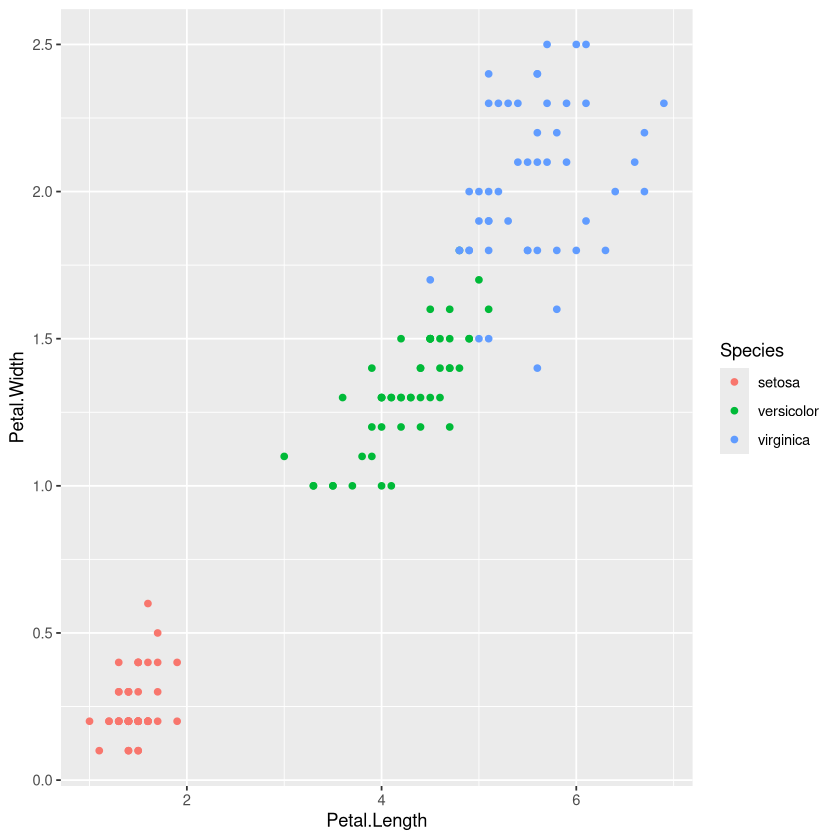

In [5]:
# Plot petal measurements by species to inspect group separation.
ggplot(iris, aes(x = Petal.Length, y = Petal.Width, color = Species)) + geom_point()

In [6]:
# Inspect feature types and dimensions in the diamonds data.
str(diamonds)

Classes ‘tbl_df’, ‘tbl’ and 'data.frame':	53940 obs. of  10 variables:
 $ carat  : num  0.23 0.21 0.23 0.29 0.31 0.24 0.24 0.26 0.22 0.23 ...
 $ cut    : Ord.factor w/ 5 levels "Fair"<"Good"<..: 5 4 2 4 2 3 3 3 1 3 ...
 $ color  : Ord.factor w/ 7 levels "D"<"E"<"F"<"G"<..: 2 2 2 6 7 7 6 5 2 5 ...
 $ clarity: Ord.factor w/ 8 levels "I1"<"SI2"<"SI1"<..: 2 3 5 4 2 6 7 3 4 5 ...
 $ depth  : num  61.5 59.8 56.9 62.4 63.3 62.8 62.3 61.9 65.1 59.4 ...
 $ table  : num  55 61 65 58 58 57 57 55 61 61 ...
 $ price  : int  326 326 327 334 335 336 336 337 337 338 ...
 $ x      : num  3.95 3.89 4.05 4.2 4.34 3.94 3.95 4.07 3.87 4 ...
 $ y      : num  3.98 3.84 4.07 4.23 4.35 3.96 3.98 4.11 3.78 4.05 ...
 $ z      : num  2.43 2.31 2.31 2.63 2.75 2.48 2.47 2.53 2.49 2.39 ...


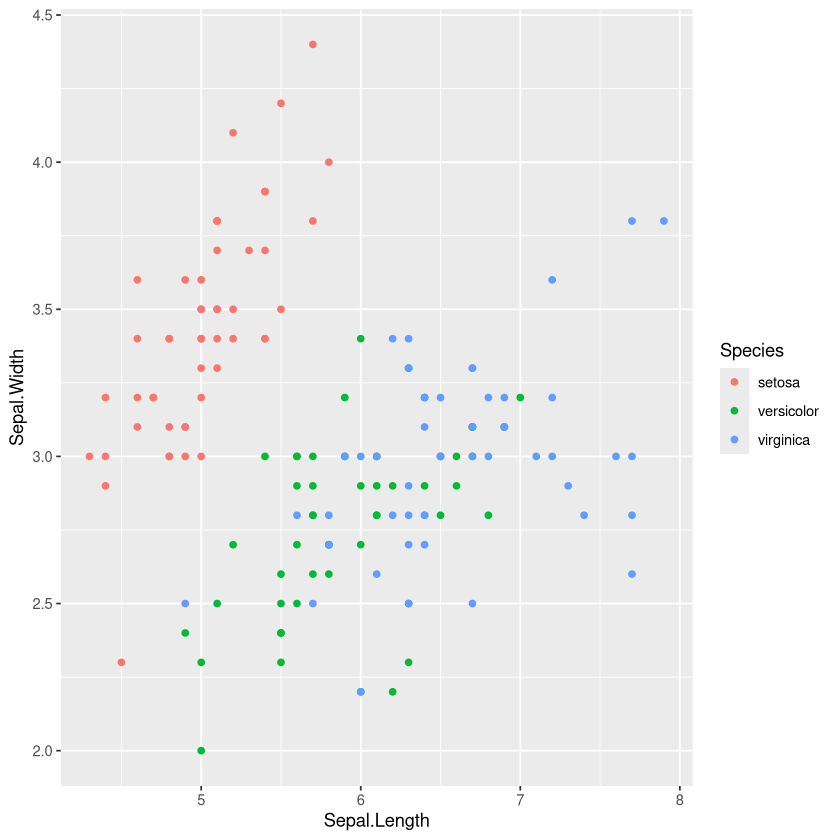

In [7]:
# Compare sepal measurements across iris species.
ggplot(iris, aes(x = Sepal.Length, y = Sepal.Width, color = Species)) + geom_point()

## Scale, sampling, and outliers


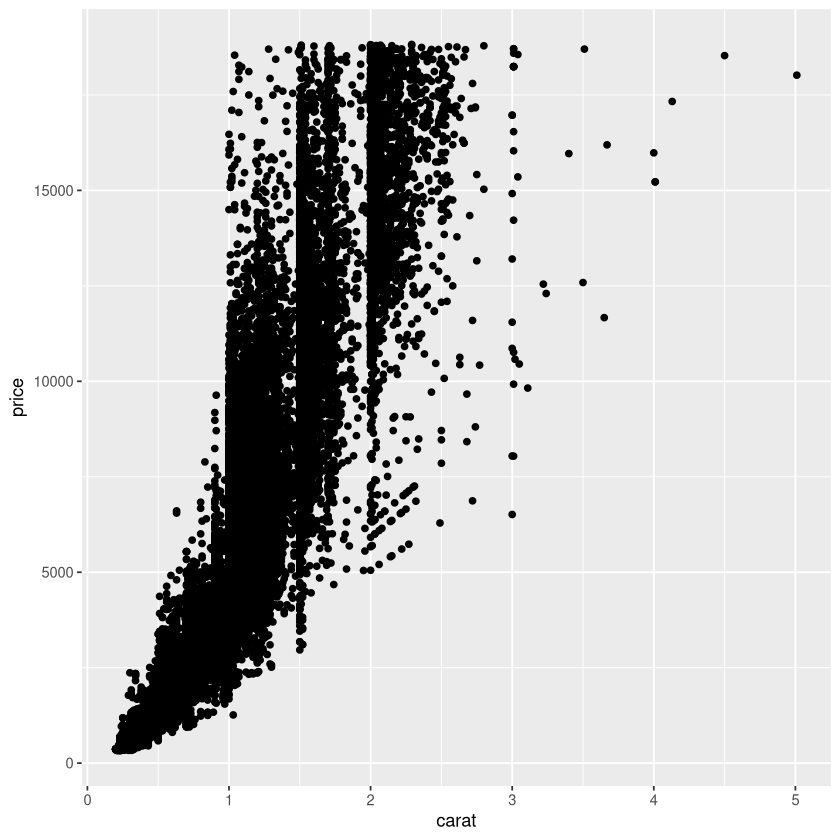

In [8]:
# Relate diamond carat weight to price.
ggplot(diamonds, aes(x = carat, y = price)) + geom_point()

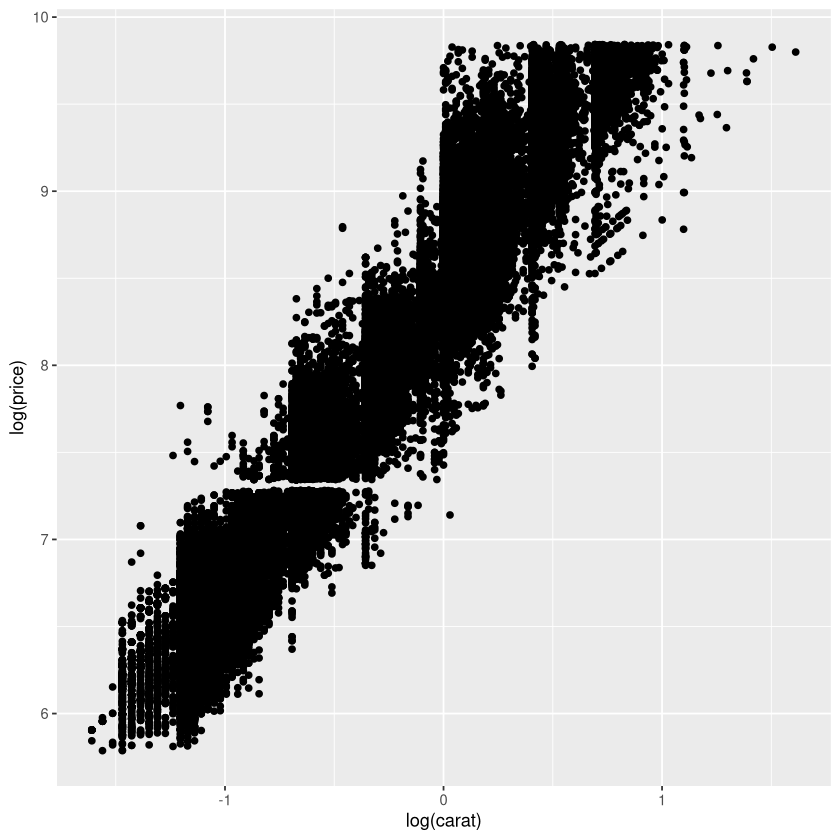

In [9]:
# Inspect the relationship on log-transformed axes.
ggplot(diamonds, aes(x = log(carat), y = log(price))) + geom_point()

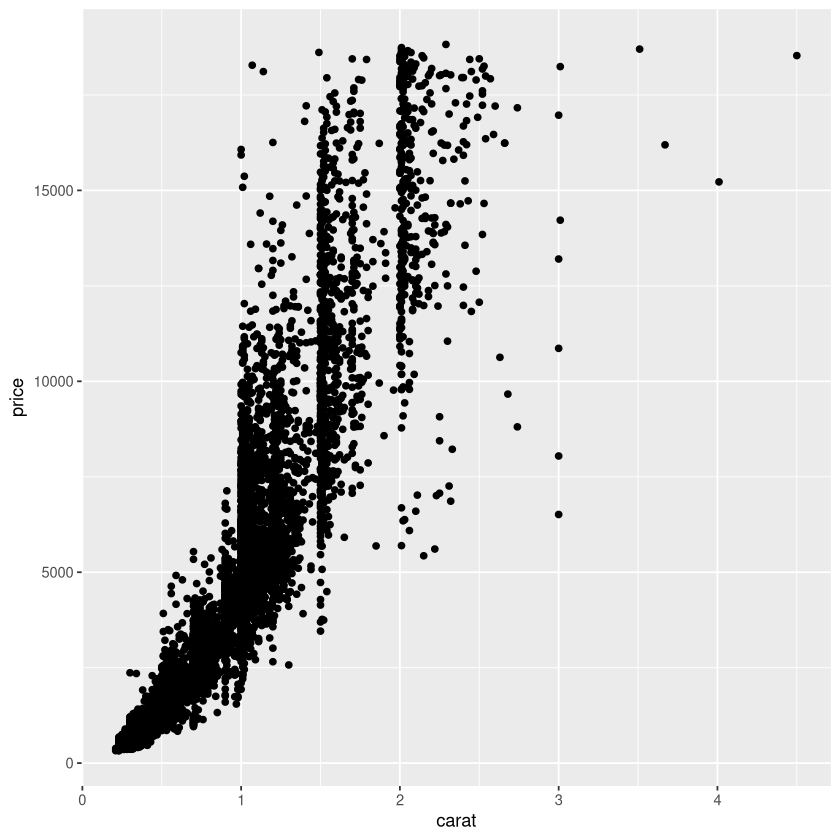

In [10]:
# Draw a random subset to reduce visual congestion in the raw scatter plot.
ggplot(diamonds[sample(nrow(diamonds), 10000), ], aes(x = carat, y = price)) + geom_point()

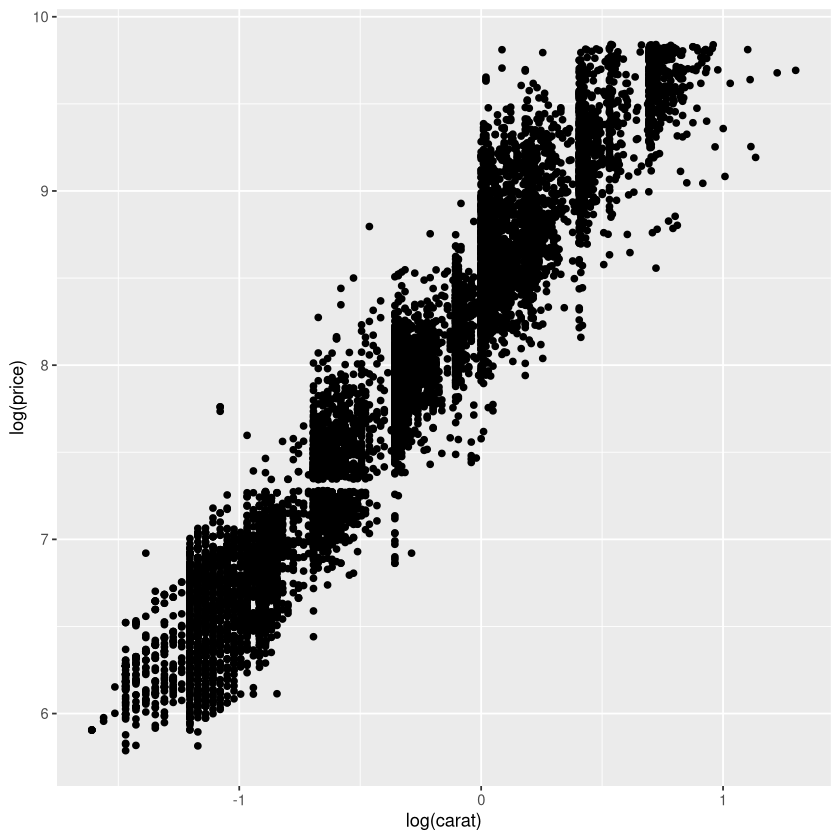

In [11]:
# Apply the same sampling idea to the logarithmic view.
ggplot(diamonds[sample(nrow(diamonds), 10000), ], aes(x = log(carat), y = log(price))) + geom_point()

[1] 53940

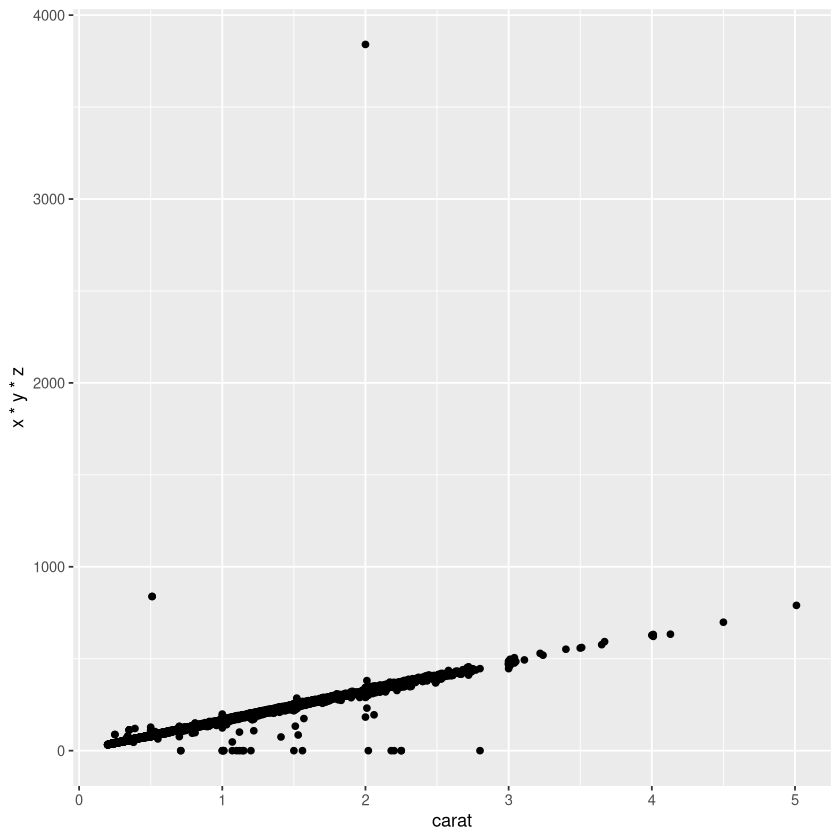

In [12]:
# Use the product of the three dimensions as a volume proxy.
nrow(diamonds)
ggplot(diamonds, aes(x = carat, y = x * y * z)) + geom_point()

### Check unusually large observations

The apparent extremes in the volume proxy deserve inspection. Confirm units, measurements, and feature definitions before treating points as invalid.


In [13]:
# Select a reproducible subset of 500 diamonds for focused exploration.
set.seed(639245)
dsmall <- diamonds[sample(nrow(diamonds),500),] 
summary(dsmall)

     carat               cut      color     clarity        depth      
 Min.   :0.2300   Fair     : 17   D:65   SI1    :117   Min.   :55.00  
 1st Qu.:0.4100   Good     : 51   E:90   VS2    :107   1st Qu.:61.20  
 Median :0.7000   Very Good:132   F:91   VS1    : 83   Median :61.90  
 Mean   :0.7753   Premium  :111   G:99   SI2    : 81   Mean   :61.91  
 3rd Qu.:1.0300   Ideal    :189   H:83   VVS2   : 61   3rd Qu.:62.70  
 Max.   :2.3000                   I:47   VVS1   : 30   Max.   :69.50  
                                  J:25   (Other): 21                  
     table          price               x               y        
 Min.   :44.0   Min.   :  345.0   Min.   :3.910   Min.   :3.940  
 1st Qu.:56.0   1st Qu.:  964.8   1st Qu.:4.730   1st Qu.:4.740  
 Median :57.0   Median : 2403.0   Median :5.675   Median :5.655  
 Mean   :57.3   Mean   : 3770.8   Mean   :5.686   Mean   :5.690  
 3rd Qu.:59.0   3rd Qu.: 5190.0   3rd Qu.:6.482   3rd Qu.:6.490  
 Max.   :66.0   Max.   :17871.0   Ma

[1] 500

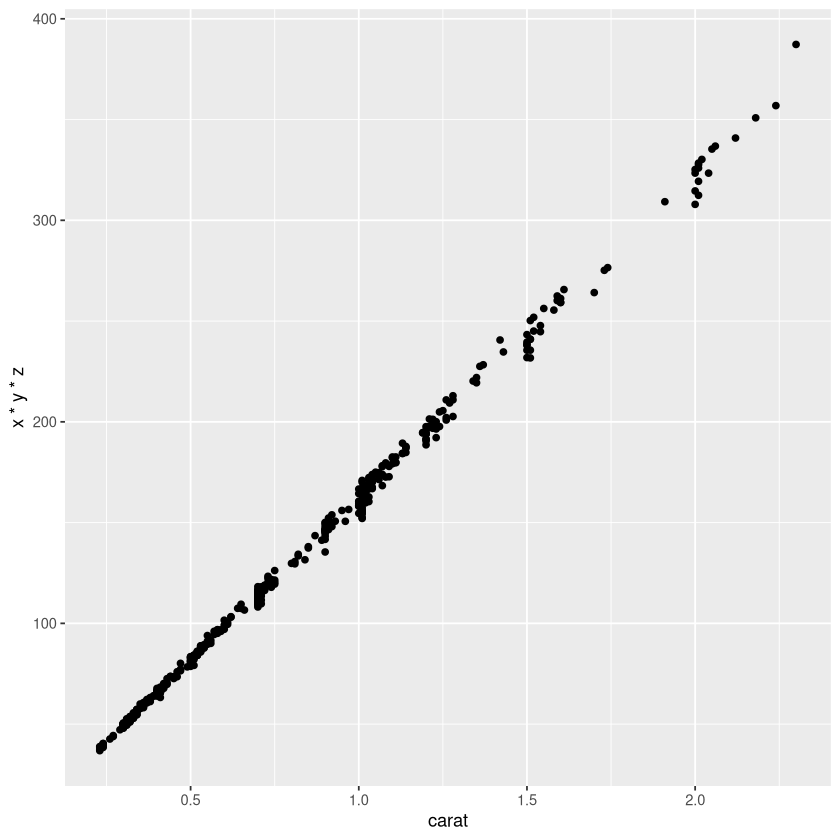

In [14]:
# Review the sampled volume proxy against carat weight.
nrow(dsmall)
ggplot(dsmall, aes(x = carat, y = x * y * z)) + geom_point()

## Aesthetic mapping and overlapping observations


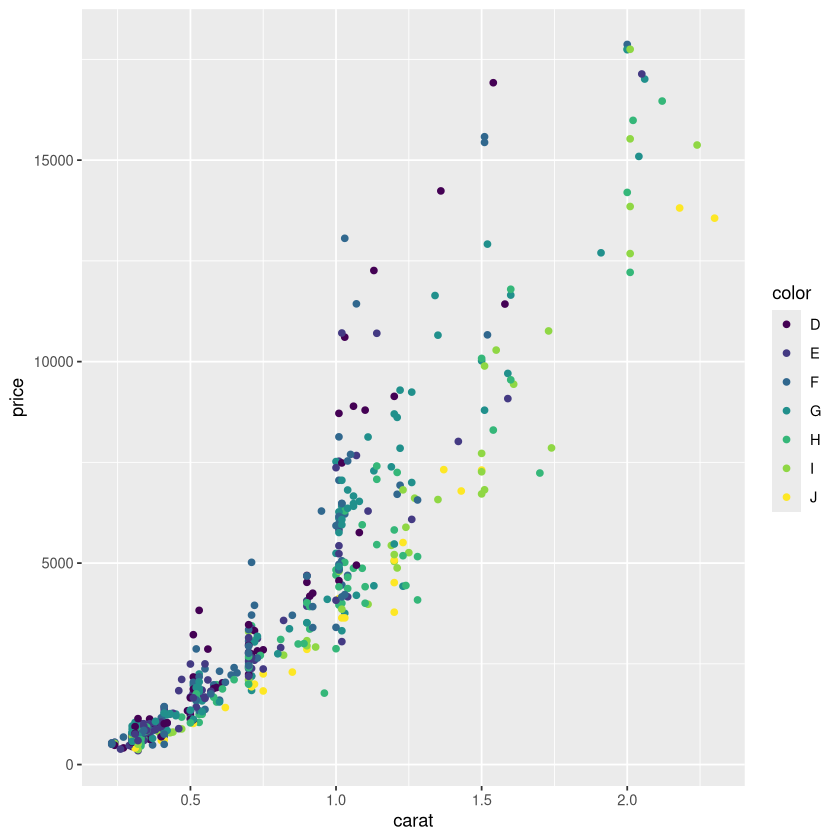

In [15]:
# Color points according to diamond color grade.
ggplot(dsmall, aes(x = carat, y = price, color = color)) + geom_point()

Warning message:
“Using shapes for an ordinal variable is not advised”


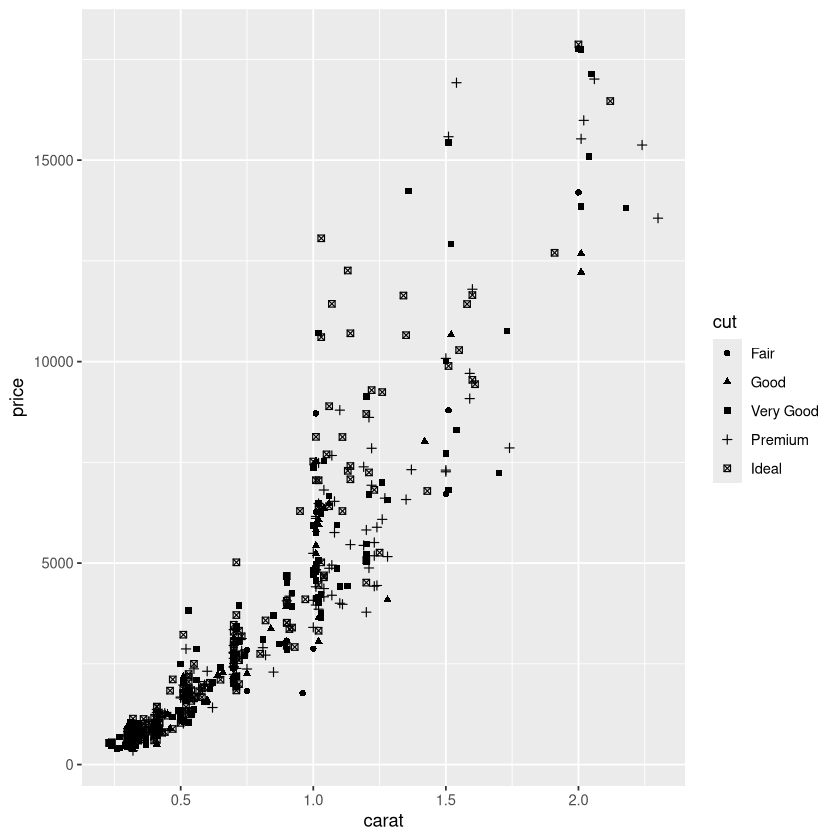

In [16]:
# Map the ordered cut quality to point shape.
ggplot(dsmall, aes(x = carat, y = price, shape = cut)) + geom_point()

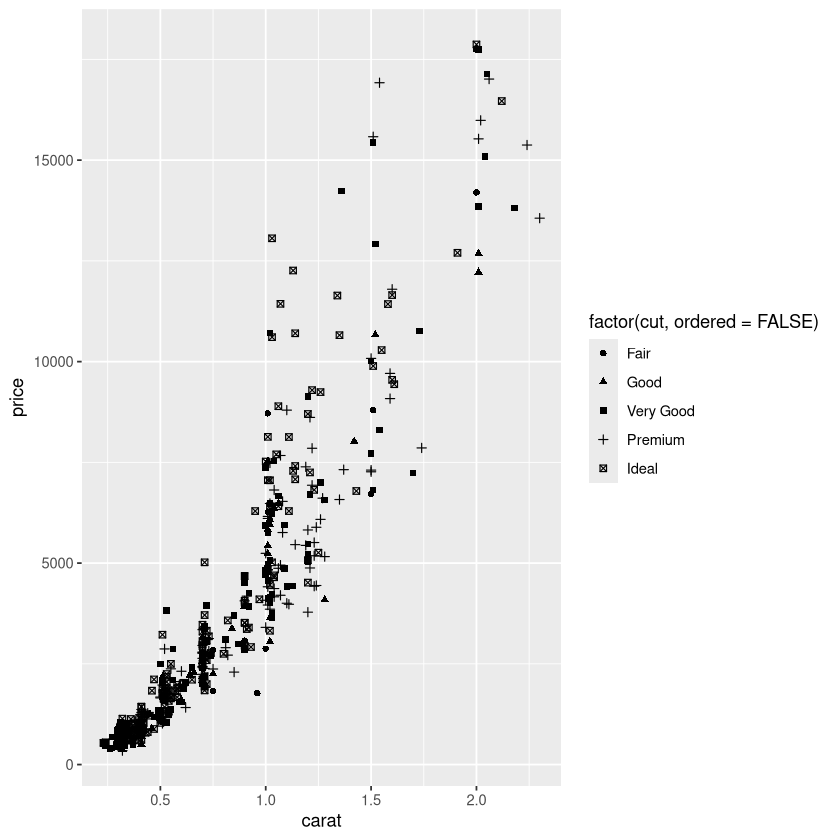

In [17]:
# Treat cut as an unordered factor when mapping shapes.
ggplot(dsmall, aes(x = carat, y = price, shape = factor(cut, ordered = FALSE))) + geom_point()

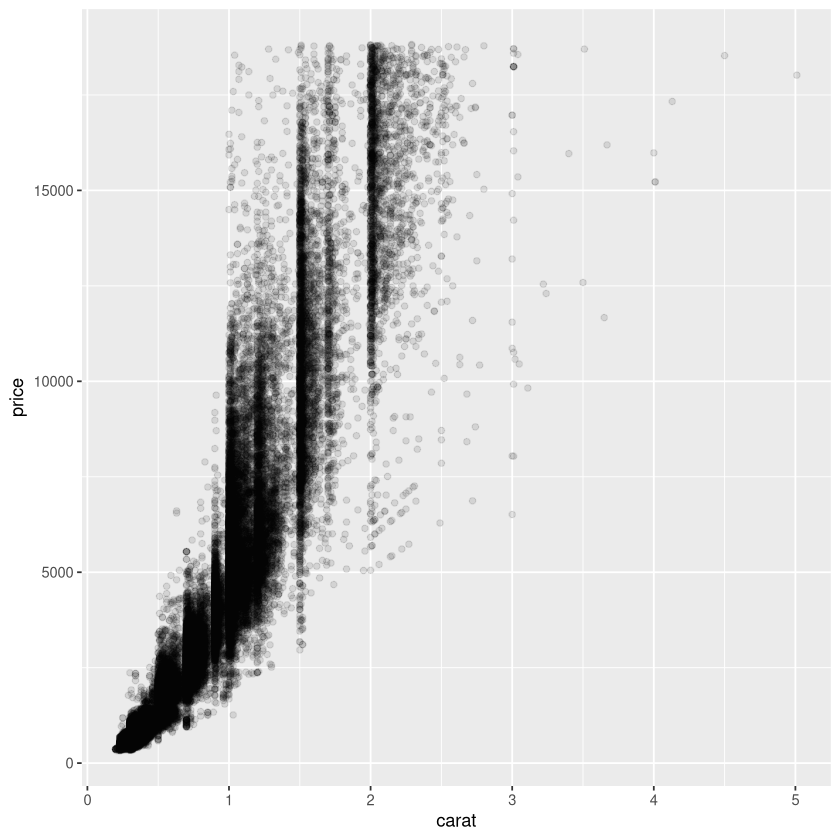

In [18]:
# Use transparency to make overlapping observations visible.
ggplot(diamonds, aes(x = carat, y = price)) + geom_point(alpha = 1/10)

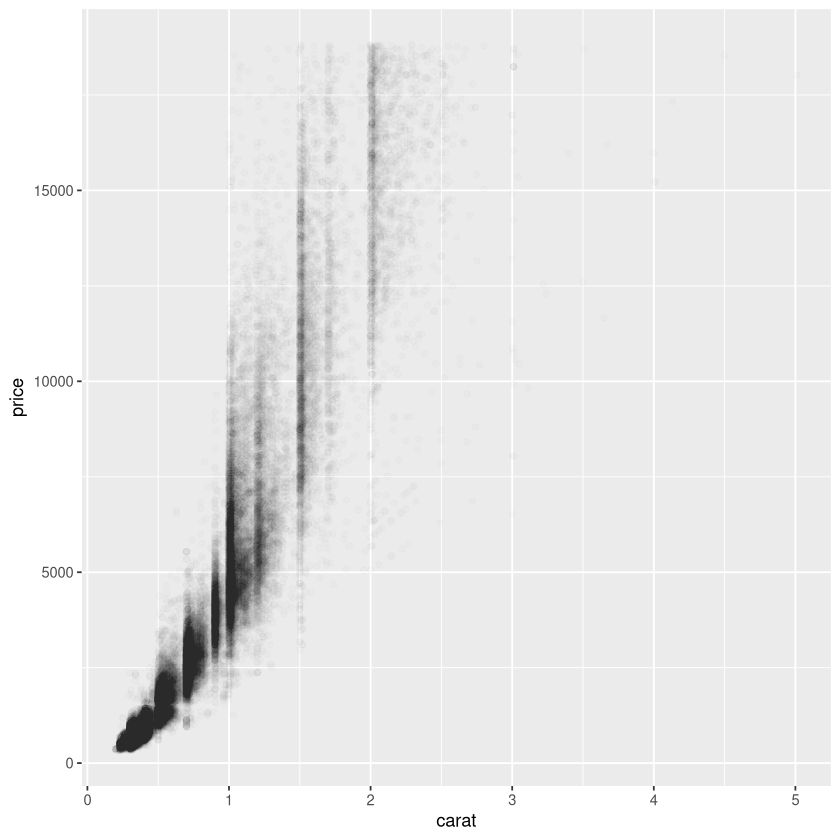

In [19]:
# Compare a stronger transparency level.
ggplot(diamonds, aes(x = carat, y = price)) + geom_point(alpha = 1/100)

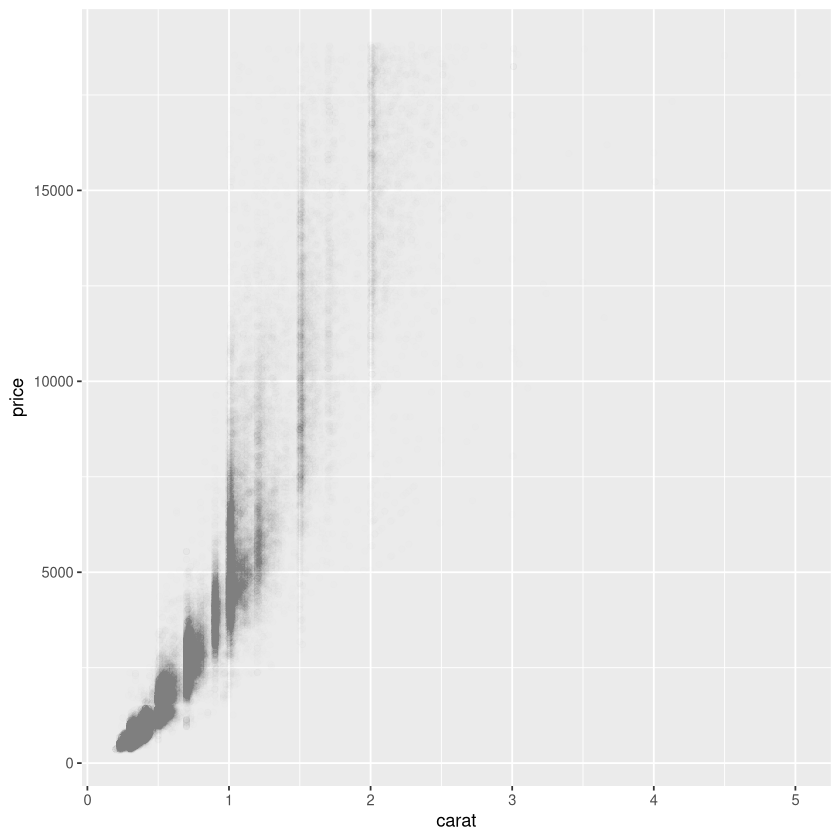

In [20]:
# Reduce opacity further for a dense point cloud.
ggplot(diamonds, aes(x = carat, y = price)) + geom_point(alpha = 1/200)

## Trend estimation and smoothing


`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


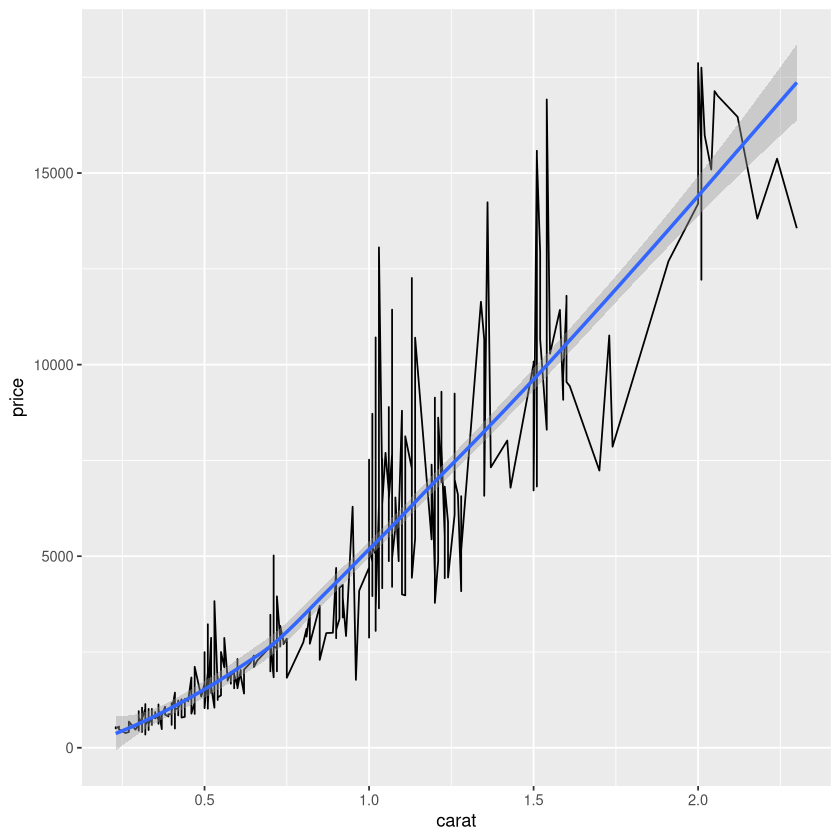

In [21]:
# Contrast connected lines with smoothed trends.
ggplot(dsmall, aes(x = carat, y = price)) + geom_line() + geom_smooth()

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


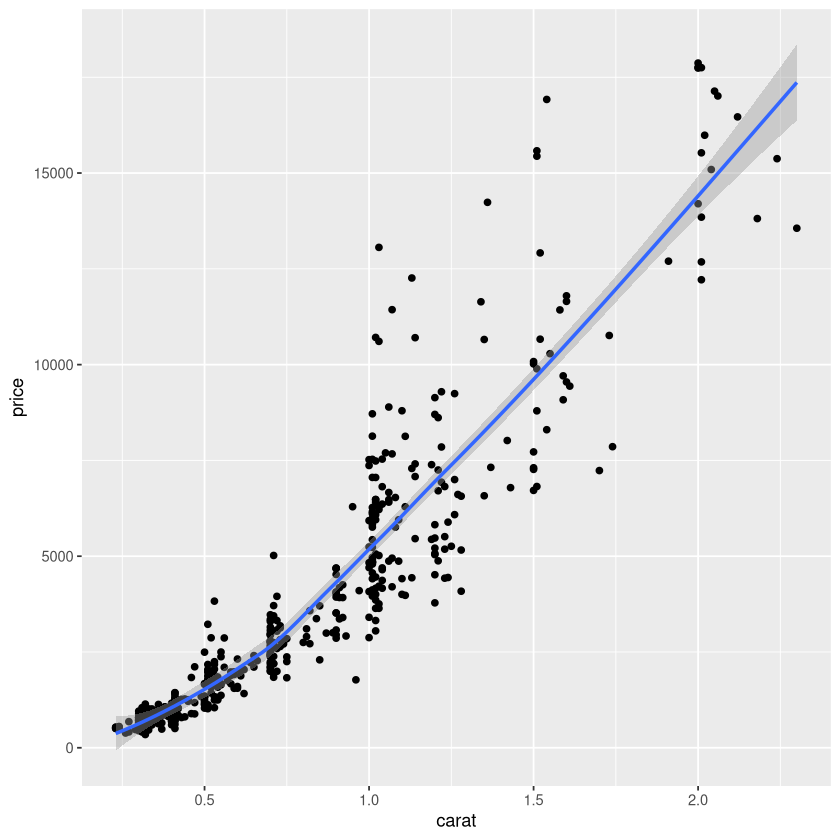

In [22]:
# Keep individual observations visible under the fitted smoother.
ggplot(dsmall, aes(x = carat, y = price)) + geom_point() + geom_smooth()

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at 0.31”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.01”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  0”
Warning message in predLoess(object$y, object$x, newx = if (is.null(newdata)) object$x else if (is.data.frame(newdata)) as.matrix(model.frame(delete.response(terms(object)), :
“pseudoinverse used at 0.31”
Warning message in predLoess(object$y, object$x, newx = if (is.null(newdata)) object$x else if (is.data.frame(newdata)) as.matrix(model.frame(delete.response(terms(object)), :
“neighborhood radius 0.01”
Warning message in predLoess(object$y, object$x, newx = if (is.null(newdata)) object$x else if (is.data.frame(newdata)) as.matrix(model.frame(delete.response(terms(object))

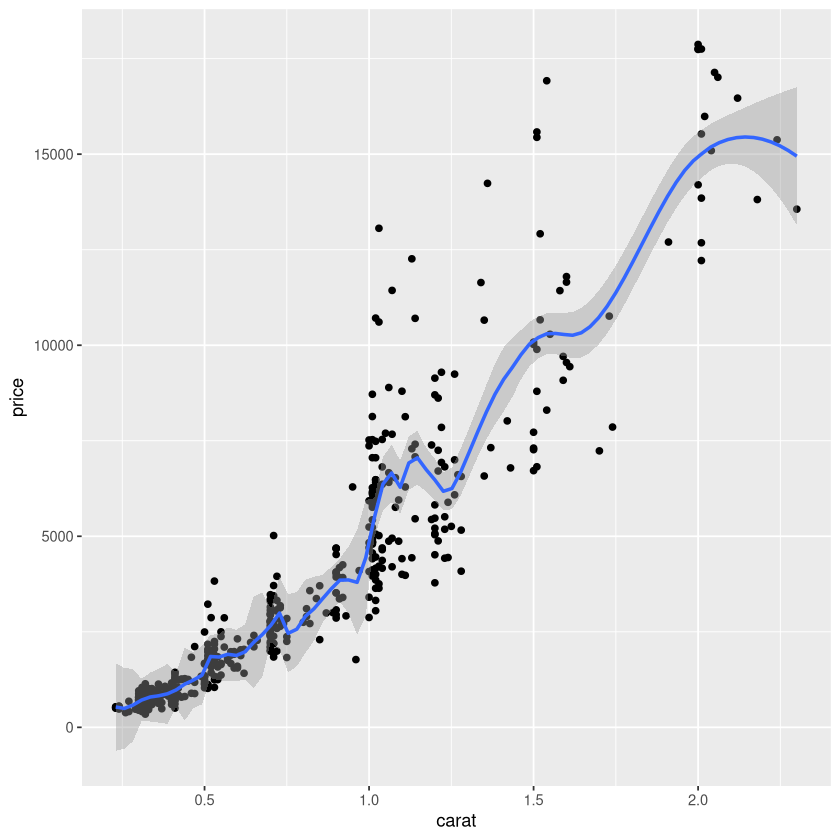

In [23]:
# Inspect the impact of a smaller smoothing span.
ggplot(dsmall, aes(x = carat, y = price)) + geom_point() + geom_smooth(span = 0.1)

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


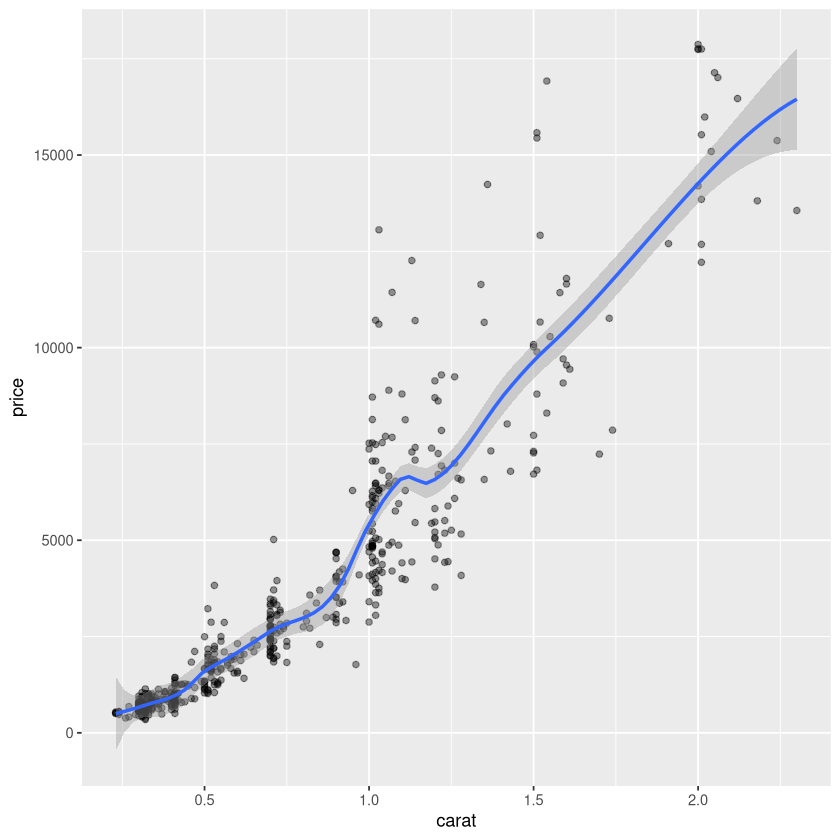

In [24]:
# Control both point opacity and local smoother flexibility.
ggplot(dsmall, aes(x = carat, y = price)) +
  geom_point(alpha = 0.4) +
  geom_smooth(span = 0.3)

`geom_smooth()` using method = 'loess' and formula = 'y ~ x'


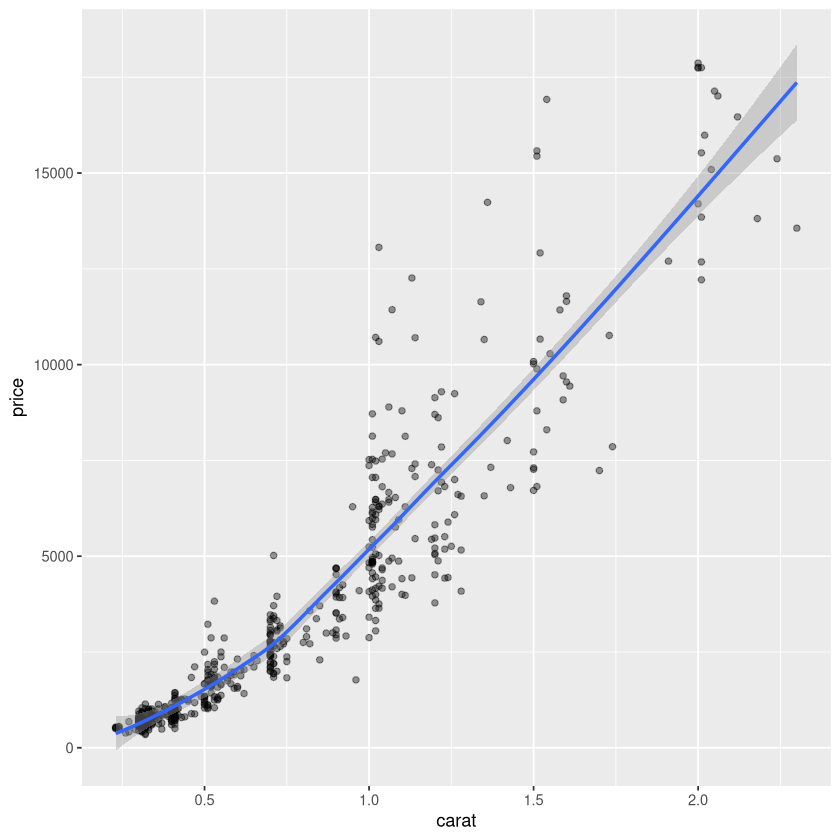

In [25]:
# Compare with a smoother using default settings.
ggplot(dsmall, aes(x = carat, y = price)) +
  geom_point(alpha = 0.4) +
  geom_smooth()

## Categorical counts and plot composition


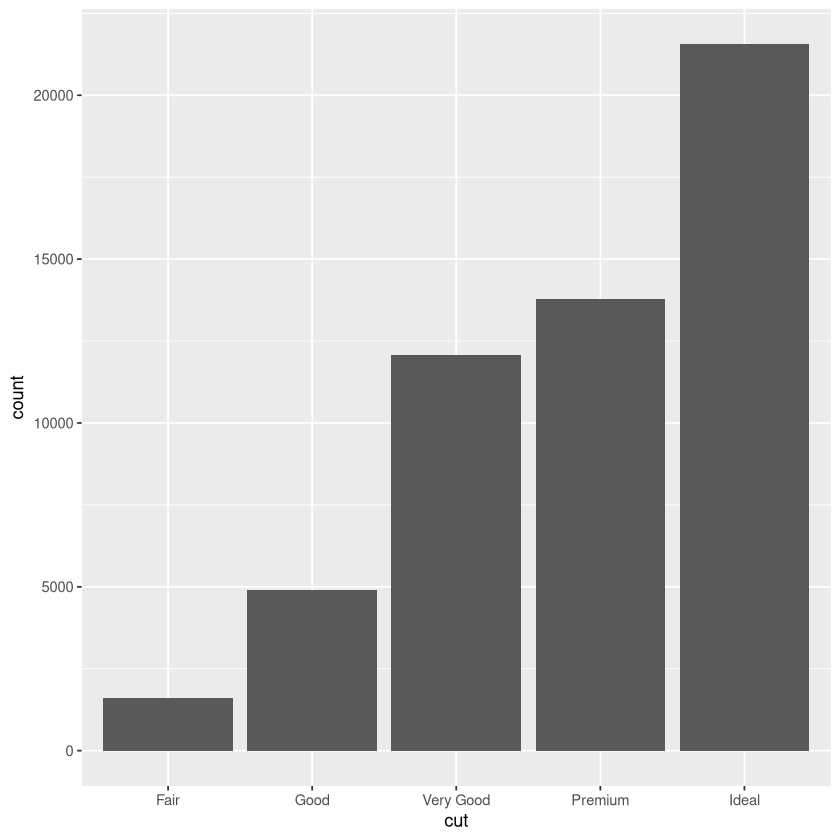

In [26]:
# Count observations in each cut category.
ggplot(diamonds, aes(x = cut)) + geom_bar()

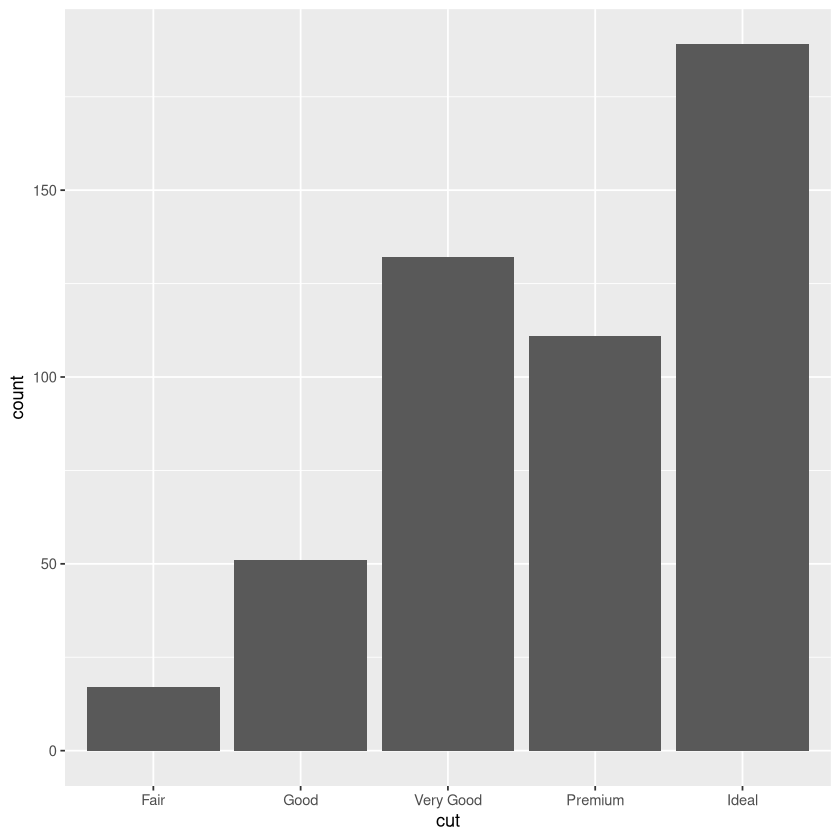

In [27]:
# Repeat the count on the smaller sample.
ggplot(dsmall, aes(x = cut)) + geom_bar()

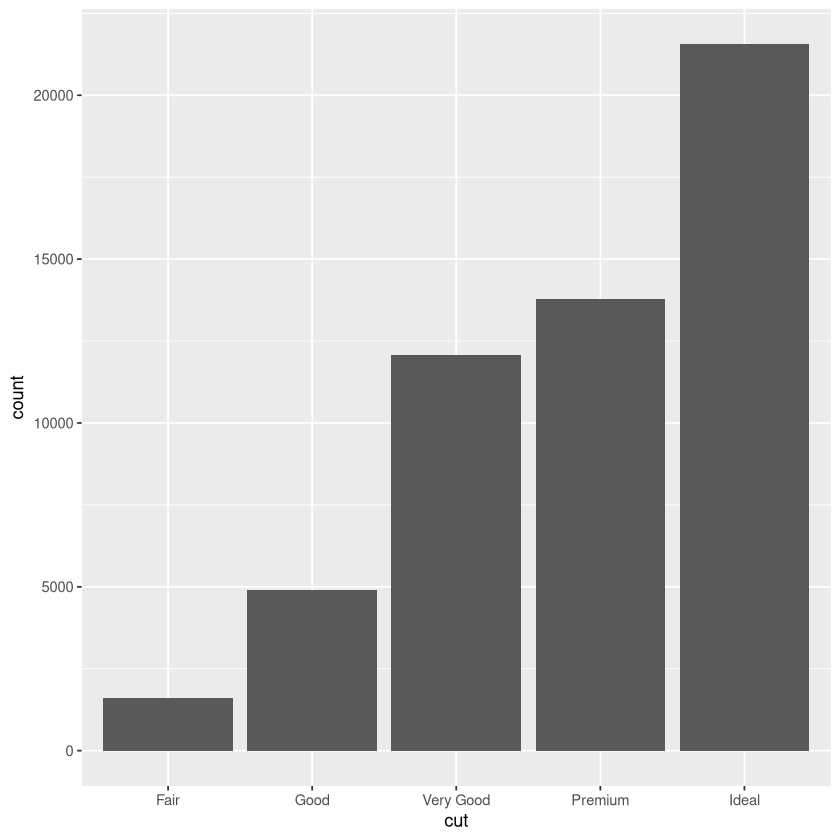

In [28]:
# Initialize a reusable ggplot object for incremental refinement.
my_plot = ggplot(diamonds, aes(x = cut)) +  geom_bar()
print(my_plot)

Warning message:
“The dot-dot notation (`..count..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(count)` instead.”


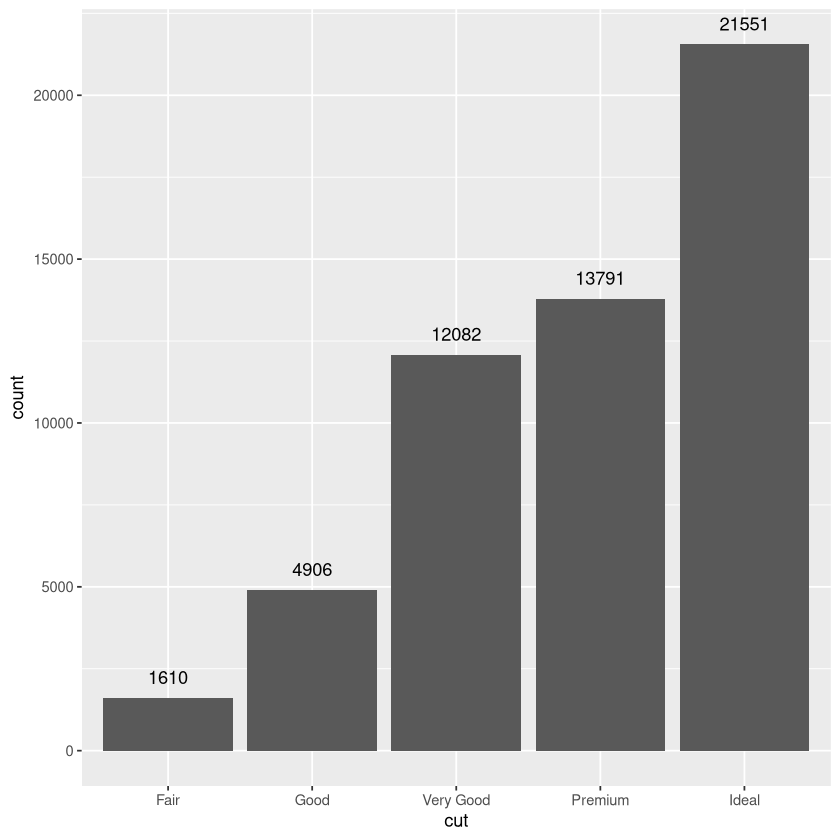

In [29]:
# Overlay the counts above each bar.
my_plot = my_plot + geom_text(stat='count', aes(label=..count..), vjust=-1)
print(my_plot)

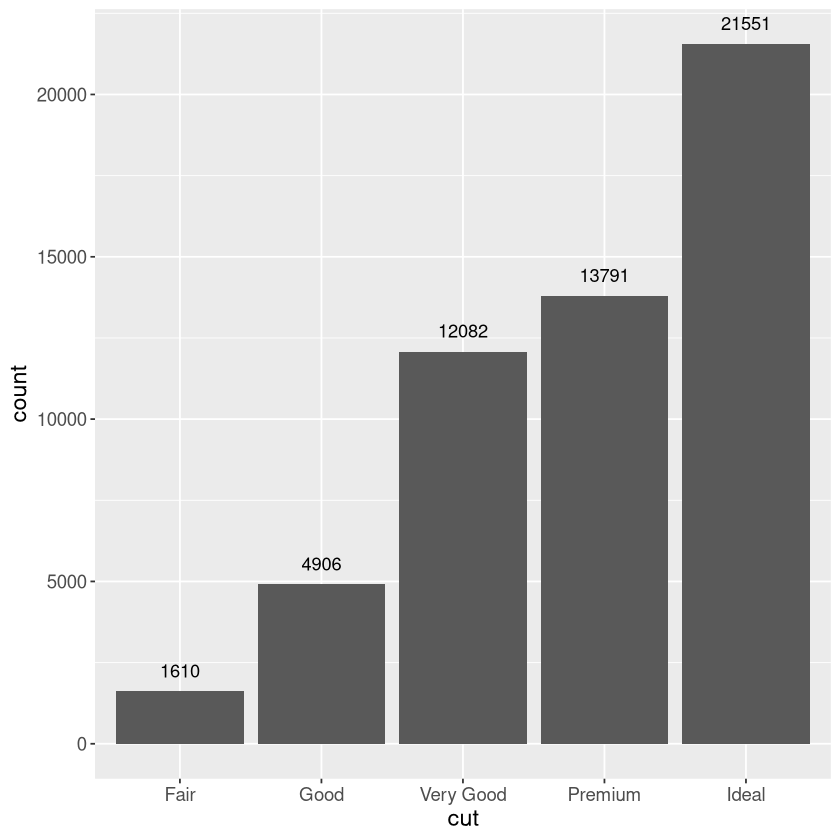

In [30]:
# Increase base text size for readability.
my_plot = my_plot +   theme(text = element_text(size = 14))
print(my_plot)

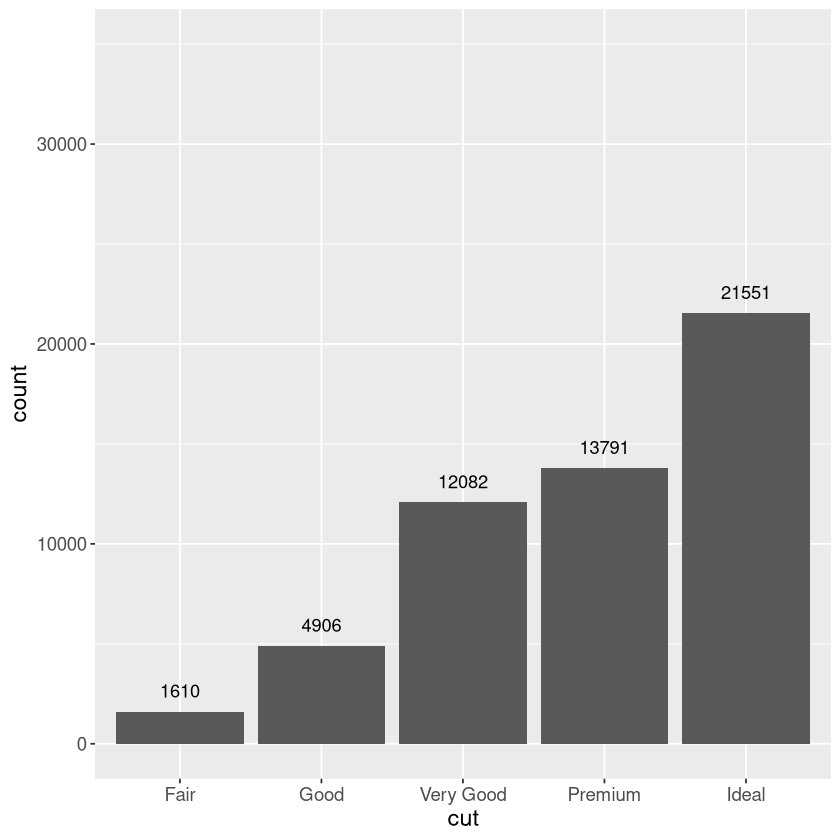

In [31]:
# Extend the vertical axis range while retaining count labels.
my_plot = my_plot + ylim(0, 35000)
print(my_plot)

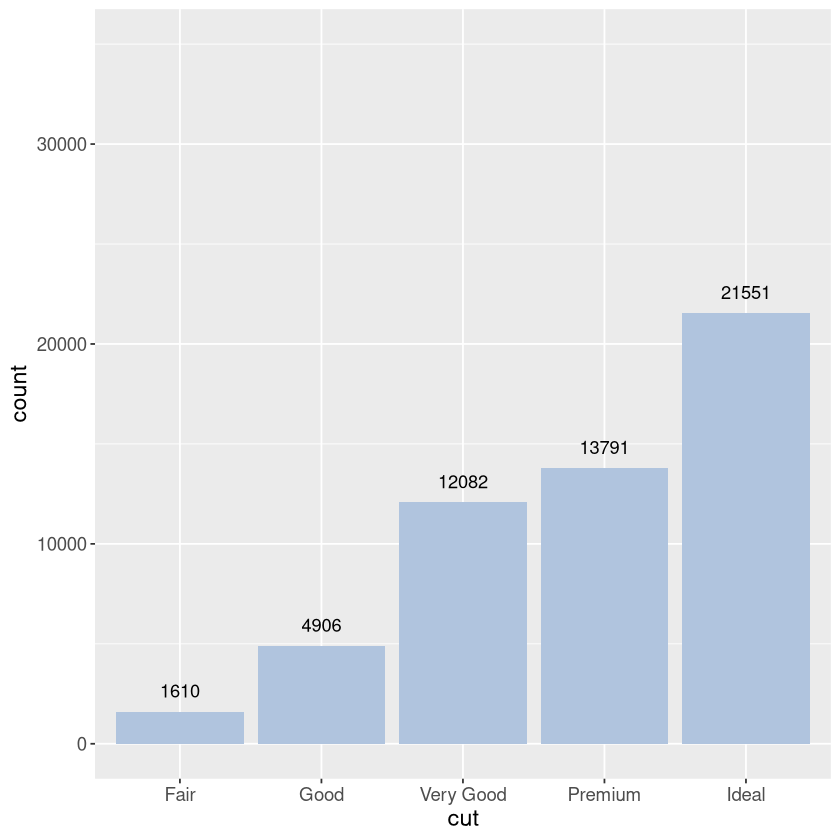

In [32]:
# Apply a consistent fill to the displayed bars.
my_plot = my_plot + geom_bar(fill = 'lightsteelblue')
print(my_plot)

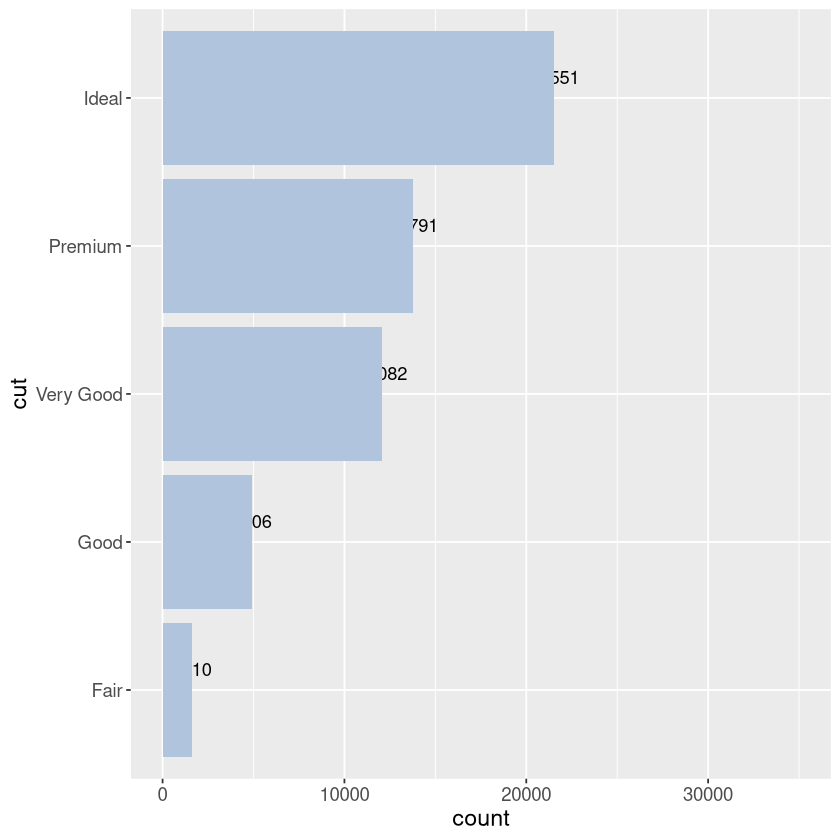

In [33]:
# Flip axes so cut labels are easier to read.
my_plot = my_plot + coord_flip()
print(my_plot)

## Distribution-oriented charts


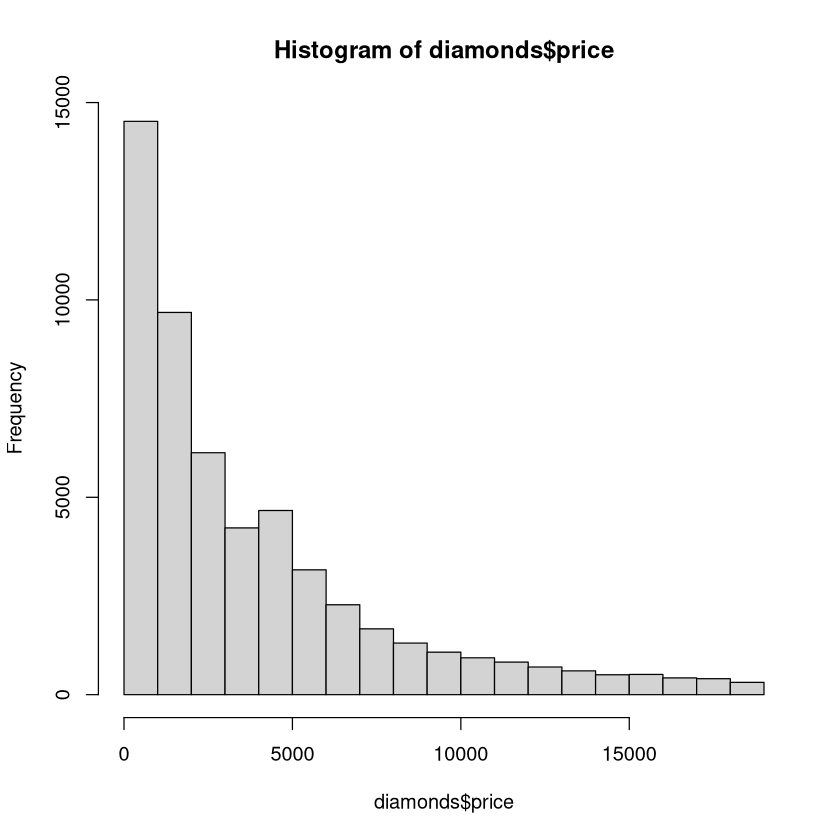

In [34]:
# Inspect the empirical distribution of price with base R.
hist(diamonds$price) 

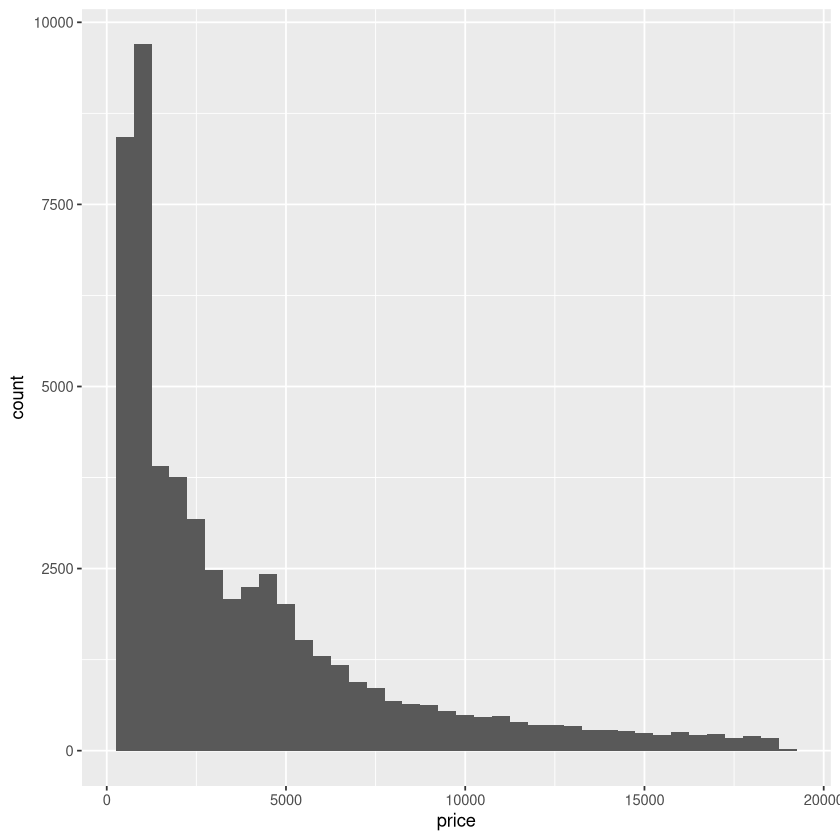

In [35]:
# Control histogram resolution with a fixed price interval.
ggplot(diamonds, aes(x = price)) + geom_histogram(binwidth = 500)

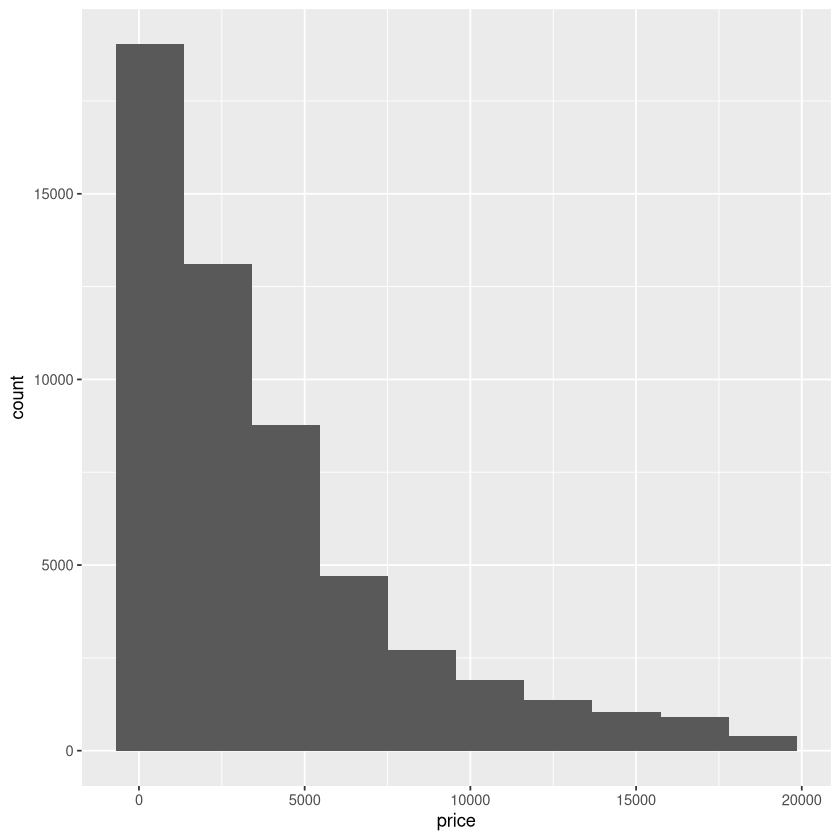

In [36]:
# Compare that view with a specified number of bins.
ggplot(diamonds, aes(x = price)) + geom_histogram(bins = 10)

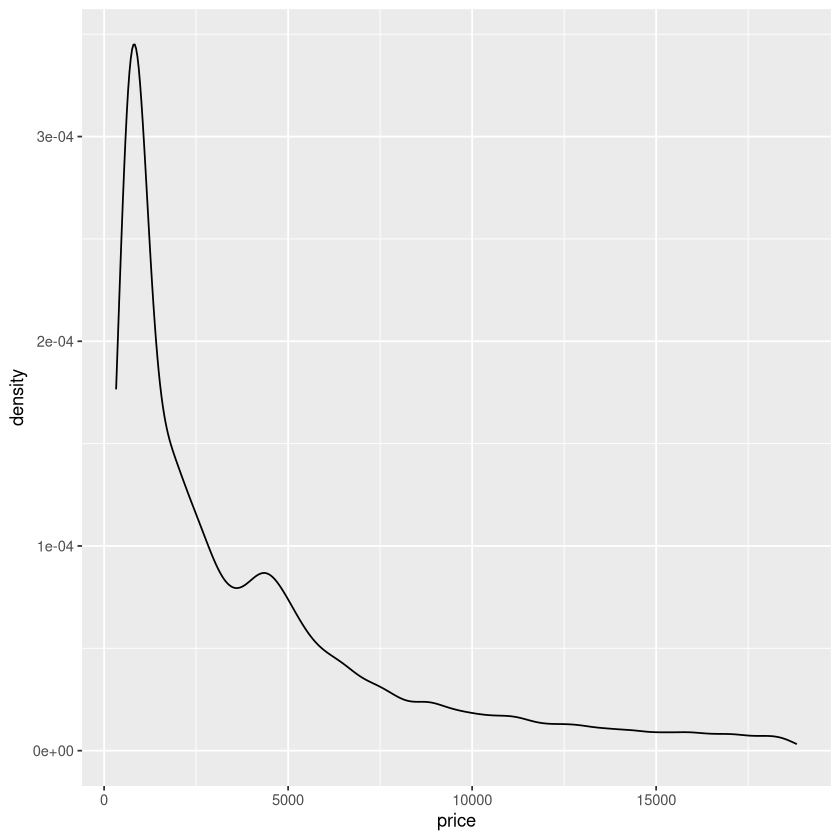

In [37]:
# Estimate price density using a smooth curve.
ggplot(diamonds, aes(x = price)) + geom_density()

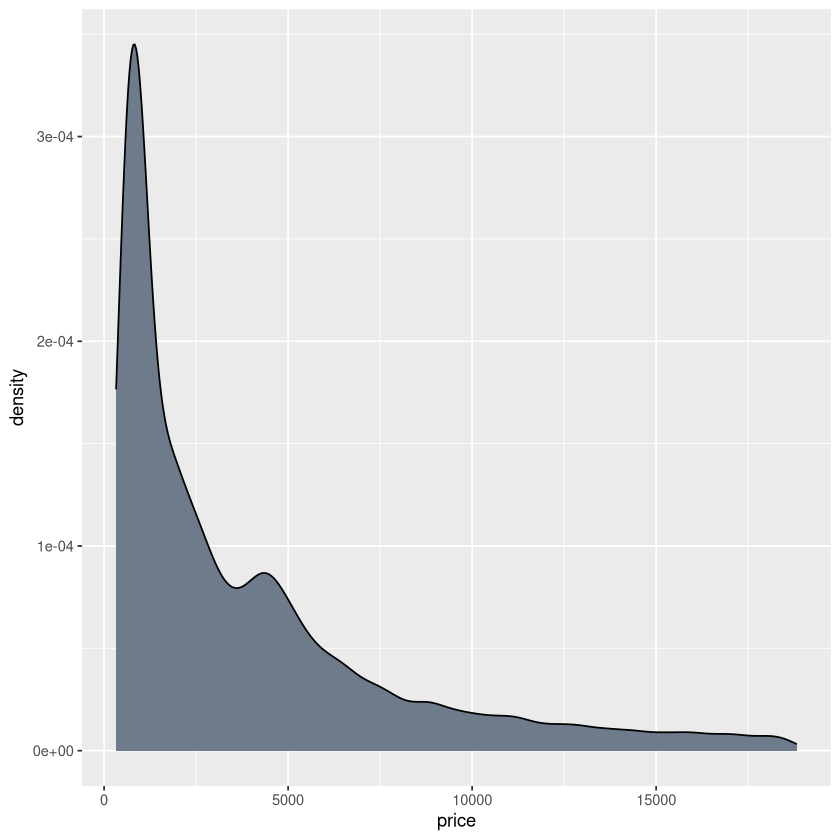

In [38]:
# Fill the price density for a stronger visual emphasis.
ggplot(diamonds, aes(x = price)) + geom_density(fill = 'lightsteelblue4')

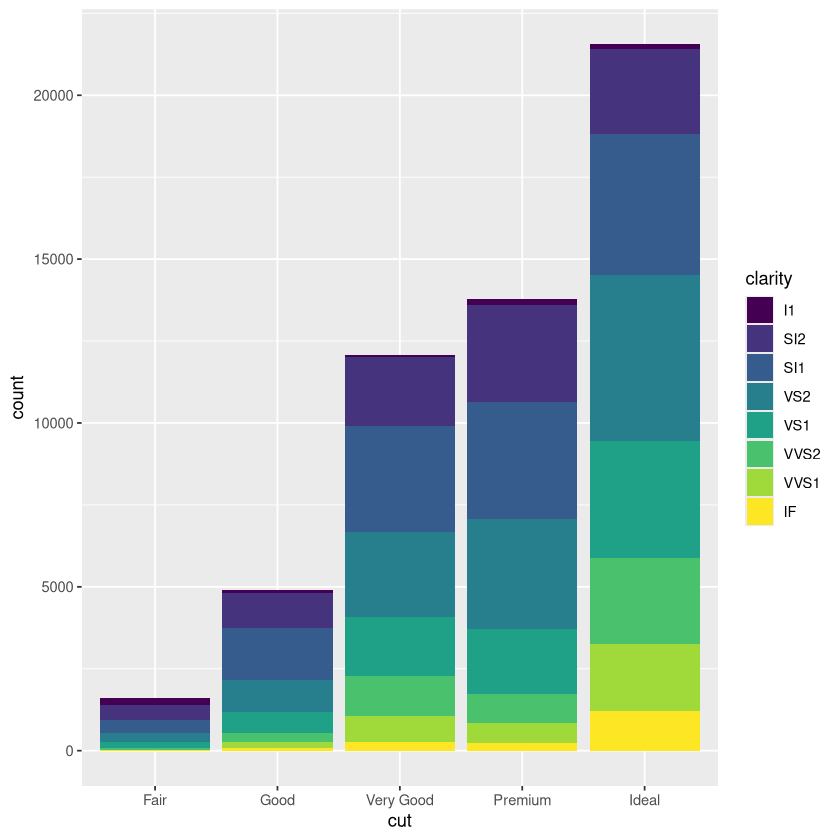

In [39]:
# Split cut counts by clarity grade using a stacked fill.
my_plot = ggplot(diamonds, aes(x = cut, fill = clarity)) + geom_bar()
my_plot

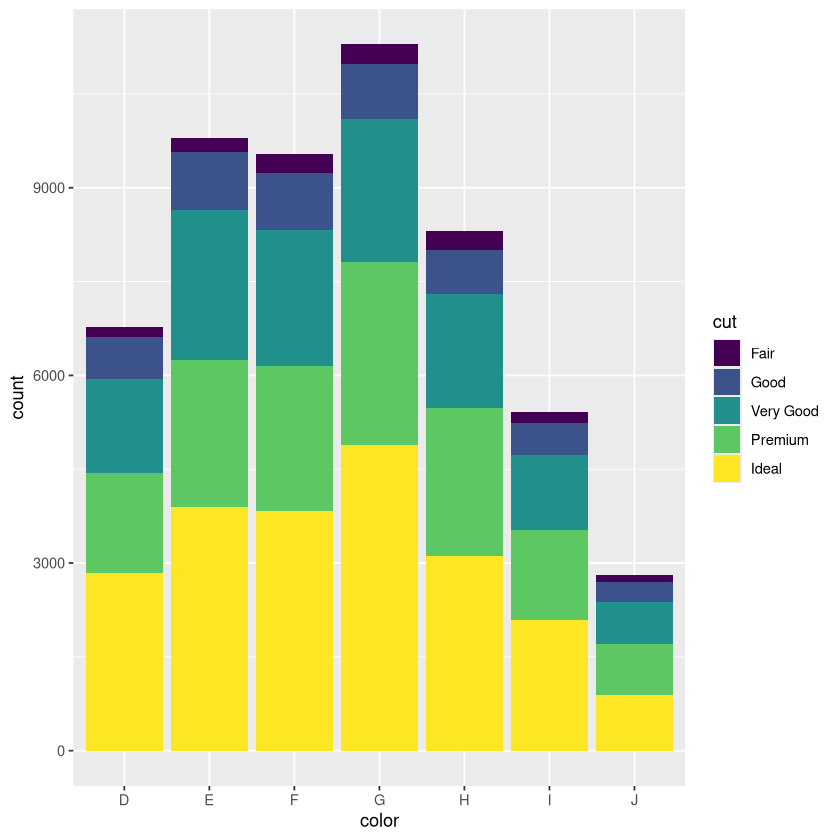

In [40]:
# Contrast diamond color groups and cut grades.
my_plot = ggplot(diamonds, aes(x = color, fill = cut)) + geom_bar()
my_plot

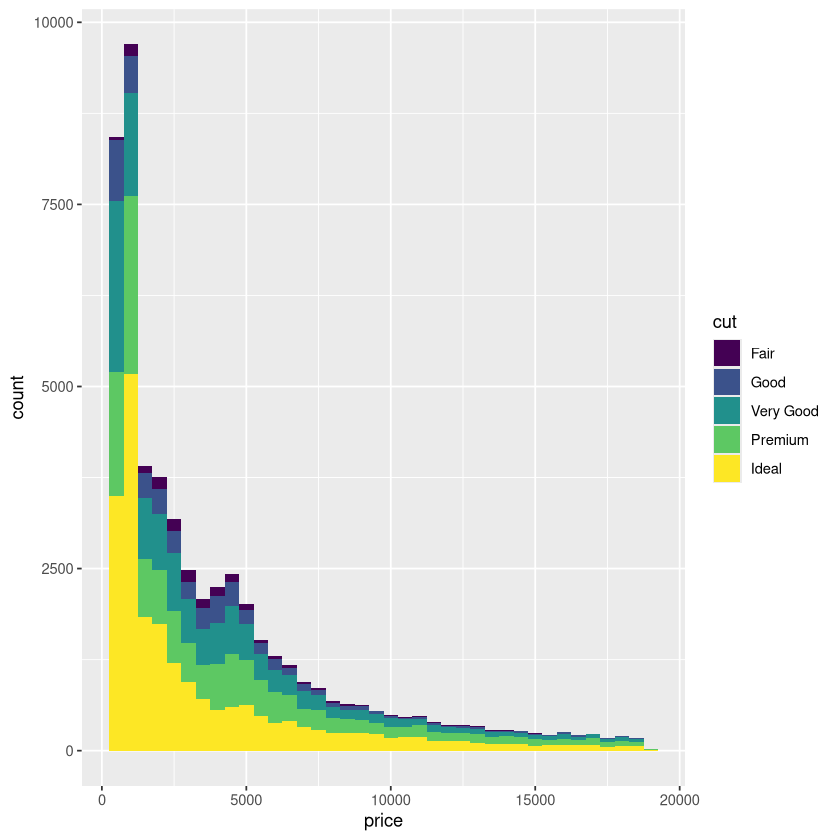

In [41]:
# Compare price distributions by cut in a histogram.
my_plot = ggplot(diamonds, aes(x = price, fill = cut)) + geom_histogram(binwidth = 500) 
my_plot

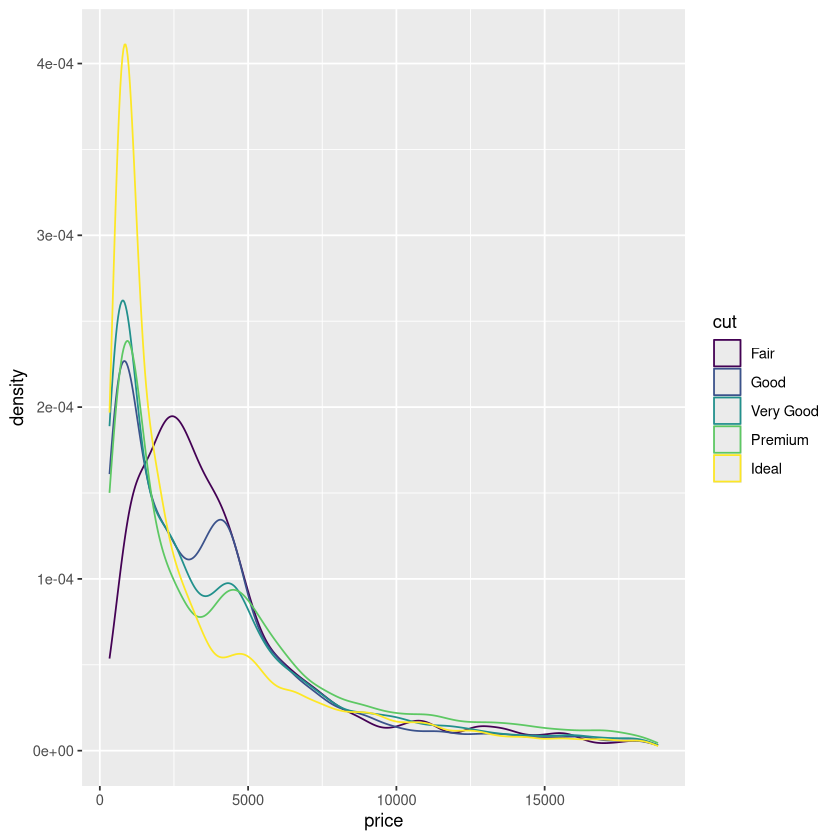

In [42]:
# Overlay category-specific density estimates.
my_plot = ggplot(diamonds, aes(x = price, color = cut)) + geom_density()
my_plot

## Group comparisons and multivariable views


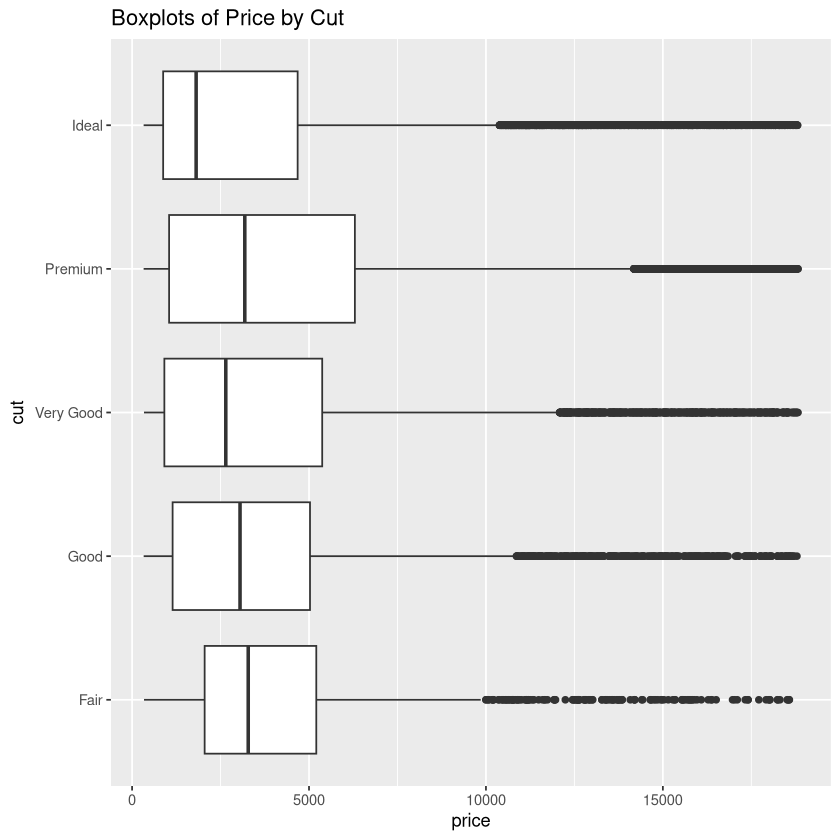

In [43]:
# Summarize price spread and outliers using boxplots.
my_plot = ggplot(diamonds, aes(x = cut, y = price)) + geom_boxplot() + coord_flip() + ggtitle("Boxplots of Price by Cut")
my_plot

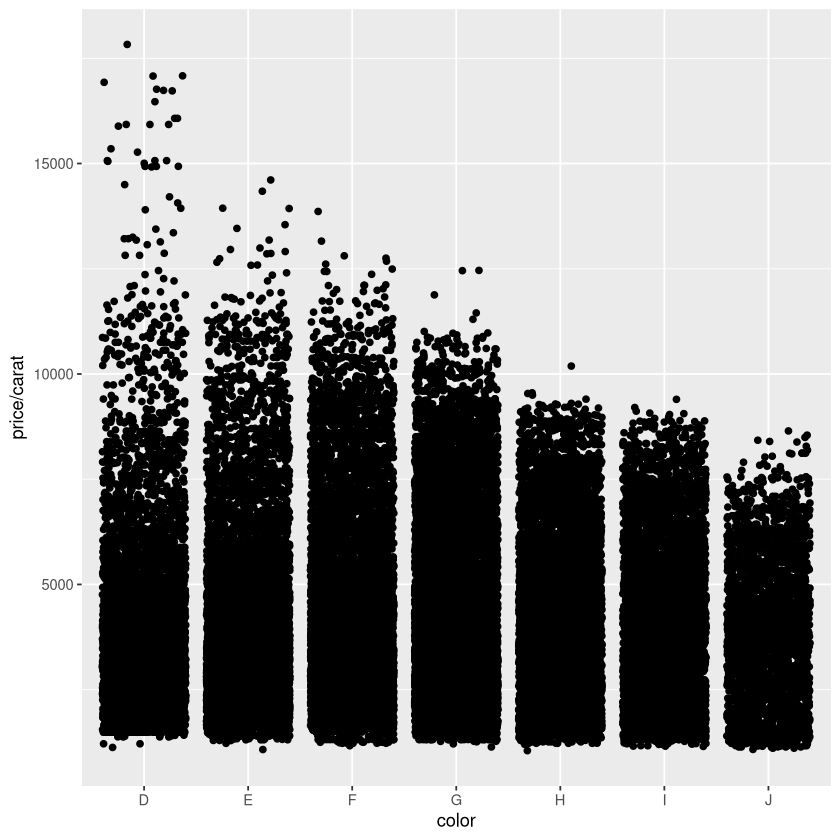

In [44]:
# Jitter overlapping prices scaled by carat.
my_plot = ggplot(diamonds, aes(x = color, y = price / carat)) + geom_jitter()
my_plot

`geom_smooth()` using formula = 'y ~ x'


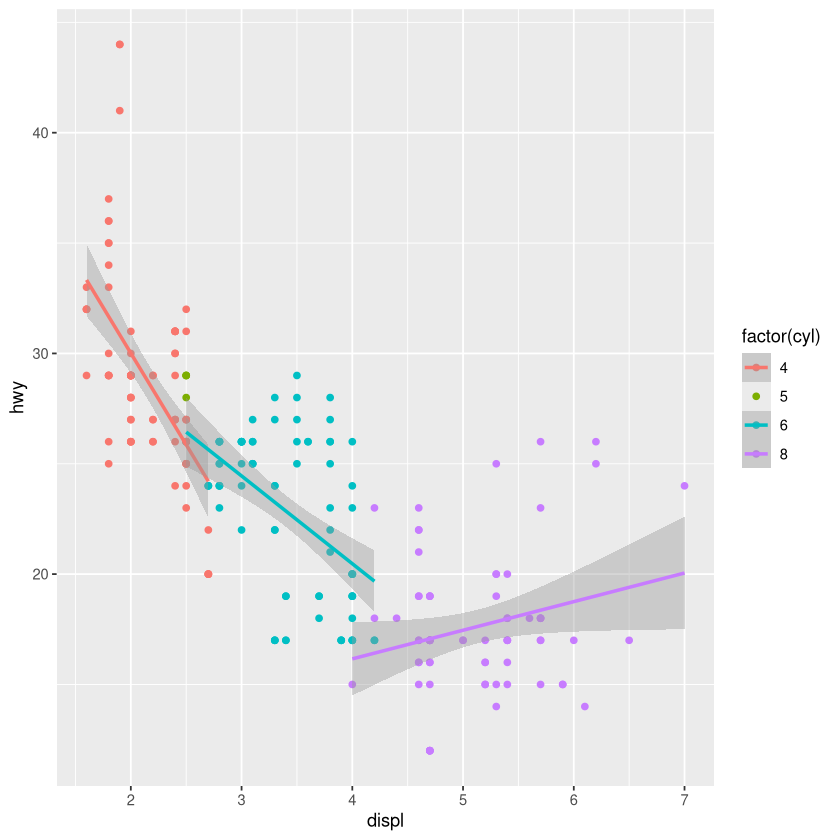

In [45]:
# Compare engine displacement with highway efficiency in the mpg example.
ggplot(mpg, aes(displ, hwy, color = factor(cyl)))+  geom_point()  + stat_smooth(method = "lm")

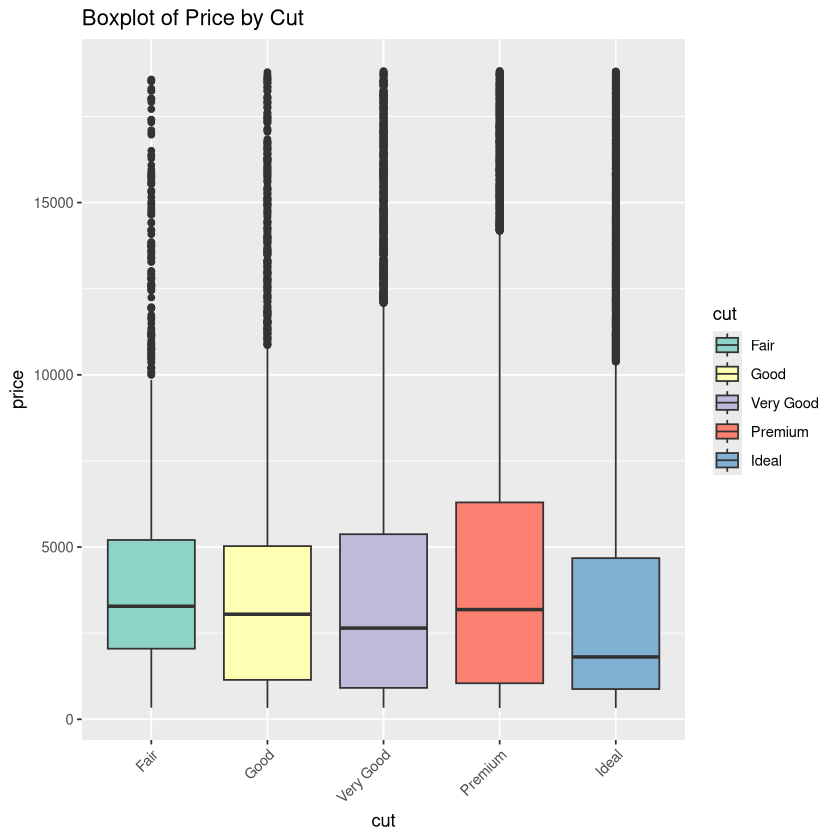

In [46]:
# Style price boxplots with a discrete palette.
ggplot(diamonds, aes(x = cut, y = price, fill = cut)) + geom_boxplot() + scale_fill_brewer(palette = "Set3") + theme(axis.text.x = element_text(angle = 45, hjust = 1)) + ggtitle("Boxplot of Price by Cut")

`geom_smooth()` using formula = 'y ~ x'


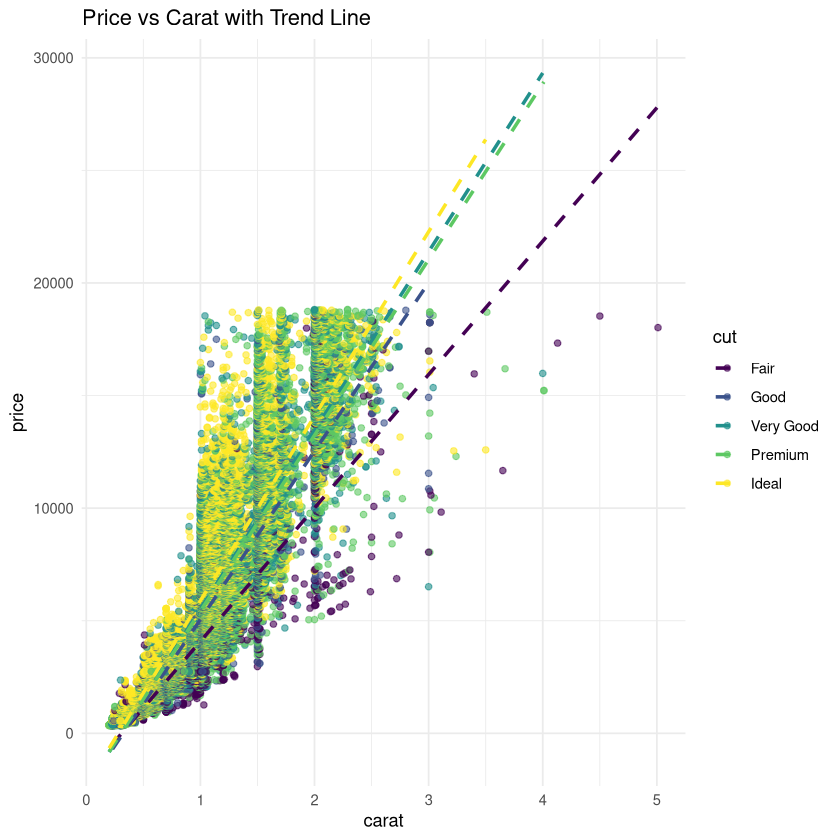

In [47]:
# Fit a separate linear price–carat trend for each cut grade.
ggplot(diamonds, aes(x = carat, y = price, color = cut)) + geom_point(alpha = 0.6) + geom_smooth(method = "lm", se = FALSE, linetype = "dashed") + theme_minimal() + ggtitle("Price vs Carat with Trend Line")

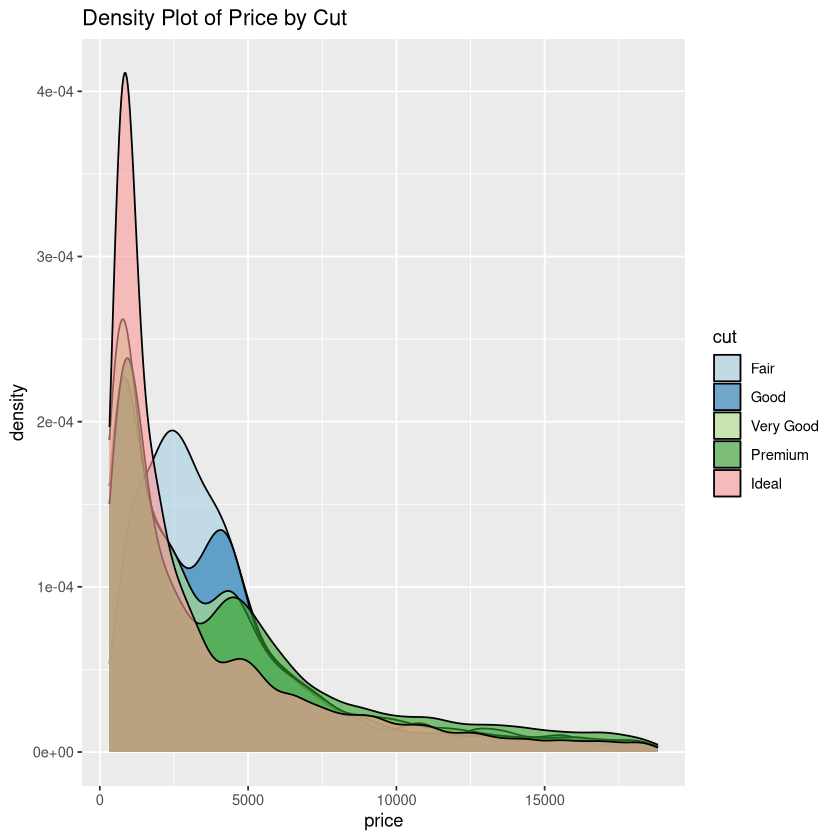

In [48]:
# Overlay price densities across cut categories.
ggplot(diamonds, aes(x = price, fill = cut)) + geom_density(alpha = 0.6) + scale_fill_brewer(palette = "Paired") + ggtitle("Density Plot of Price by Cut")

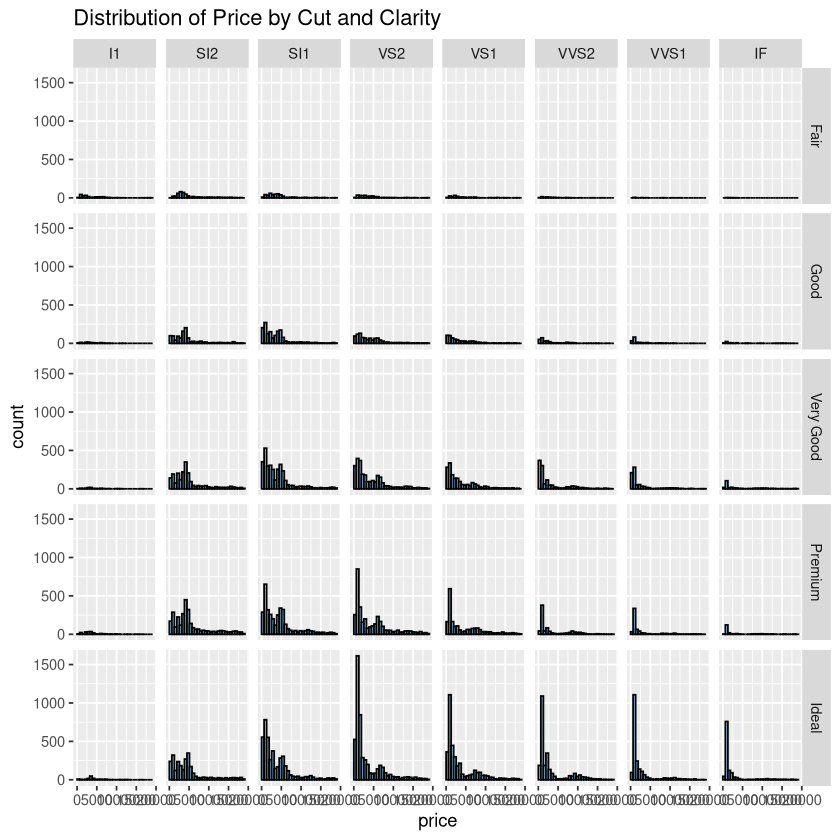

In [49]:
# Facet price histograms across cut and clarity.
ggplot(diamonds, aes(x = price)) + geom_histogram(bins = 30, fill = "skyblue", color = "black") + facet_grid(cut ~ clarity) + ggtitle("Distribution of Price by Cut and Clarity")

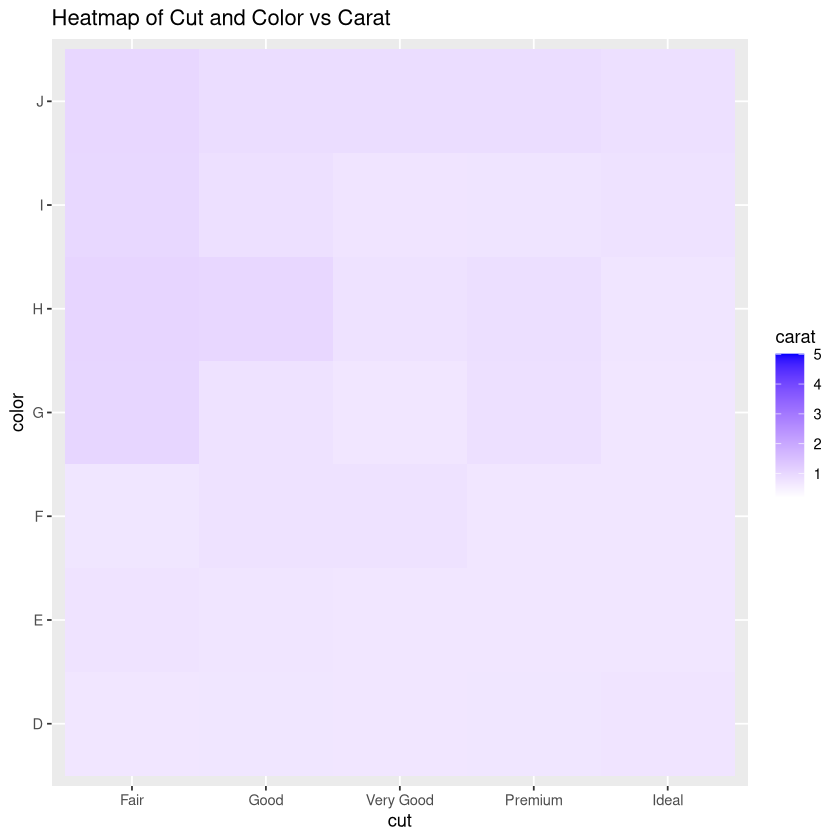

In [50]:
# Use tile color to represent carat in a categorical grid.
ggplot(diamonds, aes(x = cut, y = color, fill = carat)) +  geom_tile() +  scale_fill_gradient(low = "white", high = "blue") +  ggtitle("Heatmap of Cut and Color vs Carat")

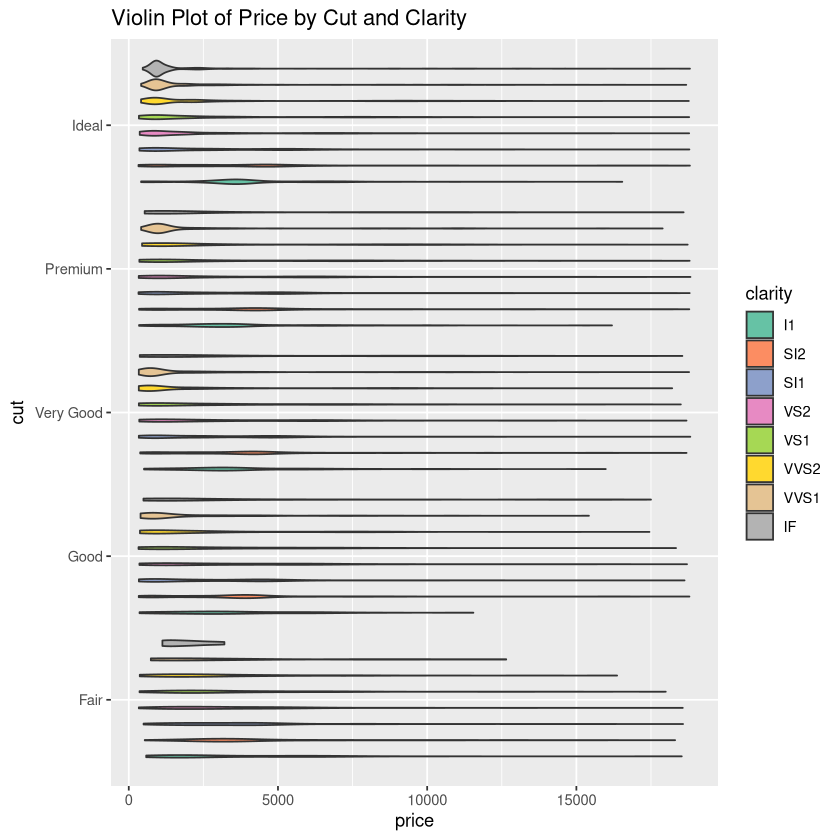

In [51]:
# Compare price densities with violin plots.
ggplot(diamonds, aes(x = cut, y = price, fill = clarity)) + geom_violin() + coord_flip() + scale_fill_brewer(palette = "Set2") + ggtitle("Violin Plot of Price by Cut and Clarity")

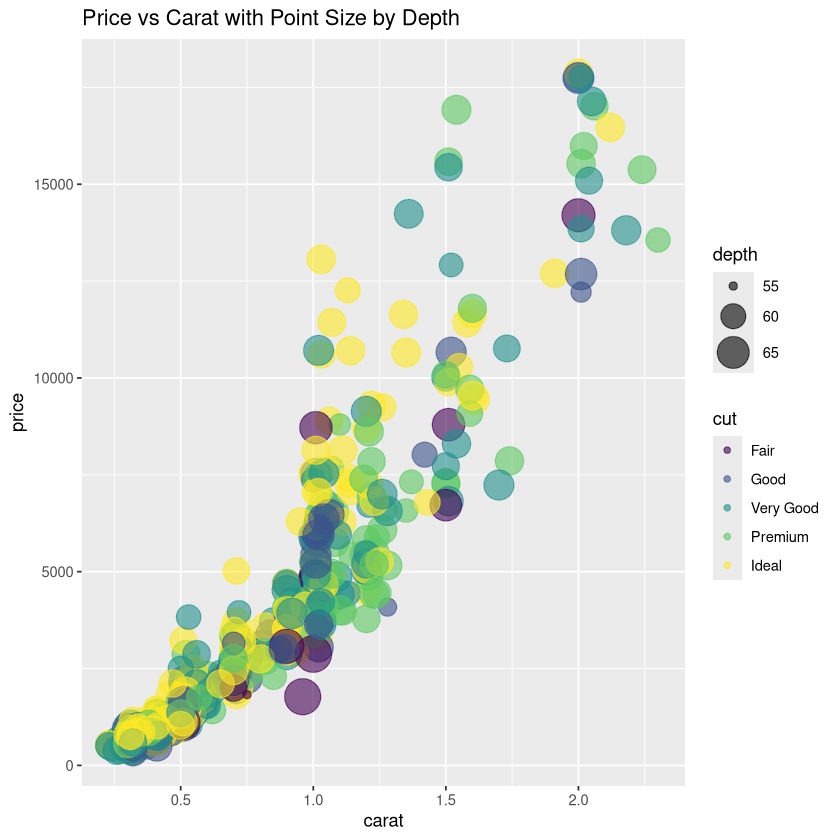

In [52]:
# Encode an additional continuous measure with point size.
ggplot(dsmall, aes(x = carat, y = price, size = depth, color = cut)) + geom_point(alpha = 0.6) + scale_size_continuous(range = c(2, 10)) + ggtitle("Price vs Carat with Point Size by Depth")